# Final checks

Collection of robustness checks for the paper. Sections:

1. **Aliasing in the bias-field pipeline** (operator construction + CIC deposit)
2. **Phase-matched muchisimocks vs. SHAMe** (cosmic-variance-free comparison)

In [21]:
import sys
from pathlib import Path

try:
    REPO_ROOT = Path(__file__).resolve().parents[1]
except NameError:
    REPO_ROOT = Path.cwd()
    if REPO_ROOT.name == "notebooks":
        REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT / "code"))
sys.path.insert(0, str(REPO_ROOT / "code_auxiliary"))

import numpy as np
from matplotlib import pyplot as plt

import paths

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Aliasing in the bias-field pipeline

How `data_creation_pipeline` builds one mock's operator fields (box $L = 1000\,h^{-1}$Mpc):

| step | grid | Nyquist $k_N=\pi N/L$ [$h$/Mpc] |
|---|---|---|
| 1. Linear field, smoothed at `damping_scale` $=0.75\,h$/Mpc; Lagrangian operators $\{1,\delta,\delta^2,s^2,\nabla^2\delta\}$ built on the particle grid | $512^3$ particles | 1.61 |
| 2. map2map moves the $512^3$ particles to their nonlinear positions | $512^3$ particles | — |
| 3. CIC **deposit** of the operator-weighted particles onto a mesh (`bacco.statistics.compute_mesh(ngrid=...)`) | deposit mesh $512^3$ | 1.61 |
| 4. **$k$-cut**: keep only modes of a $128^3$ grid | $128^3$ | 0.40 |
| 5. **Deconvolve** the CIC window of the $512^3$ deposit mesh | $128^3$ | — |

Two questions: **(1)** does building the operators (products of fields, step 1) alias? **(2)** does the deposit (step 3) alias, and is the deconvolution (step 5) exact?

### 1.1 Operators: no aliasing, by Orszag's rule

A product of two fields has power up to the sum of their wavenumbers; anything above $k_N$ wraps back. Orszag's 2/3 rule says products are alias-free if the fields are zero above $\tfrac23 k_N = 1.07\,h$/Mpc. The smoothing at $0.75$ acts as that zero padding: in bacco it is a near-sharp cut, $P(k)\to P(k)\cdot\tfrac12\,\mathrm{erfc}[\log_{10}(k/0.75)/0.01]$ (`lss_scaler/lssmodule.c`), so $\delta$ has no power above $0.75$. The quadratic operators then reach at most $1.5 < k_N = 1.61$, so nothing wraps at all, which is stronger than the 2/3 condition. No test needed.

### 1.2 Deposit and deconvolution: test with a finer deposit mesh

The particles in step 3 sit at nonlinear positions and are not band-limited, so the CIC deposit can fold power from above $k_N$ into our band, and dividing by the CIC window in step 5 cannot undo that.

**Test** (`code/test_deposit_aliasing.py`, on `muchisimocks_lib_p5_n10000_rerun/LH0`, the one mock with map2map displacements saved): keep the $512^3$ particles, positions and operator weights fixed, and change only the **deposit mesh** in step 3: $256^3$, $512^3$ (production) and $1024^3$ (reference, $k_N = 3.22$). Each is then $k$-cut to $128^3$ and deconvolved with its own deposit mesh's CIC window, exactly as in steps 4–5. If the deposit and deconvolution are fine, the three should give the same $P(k)$.

$P(k)$ is measured as in production: `compute_statistics.compute_pk`, 32 log bins from 0.01 to 0.4 $h$/Mpc, in $h^{-3}$Mpc$^3$ (`code_auxiliary/aliasing_pk_production_bins.py`). The grey band marks bins beyond the fiducial cut (`_kp0.37`). Shown for the tracer field (SHAMe-like biases, $\bar n = 2.2\times10^{-4}$). Each operator alone behaves the same way (max values are in the table).

In [22]:

dir_alias = paths.DIR_DATA / "aliasing_test" / "LH0"
# P(k) of the test fields measured with production's compute_pk (32 log bins, (Mpc/h)^3),
# written by code_auxiliary/aliasing_pk_production_bins.py
res = dict(np.load(dir_alias / "pk_production_bins.npz"))
k = res["k"]
# field-level check that the test reproduces the production field (code/test_deposit_aliasing.py)
pdiff_production = np.load(dir_alias / "summary.npz")["pdiff_tracer_production_vs_ng512"].max()

L_BOX = 1000.
ops = ["1", "delta", "delta2", "s2", "nabla2delta"]
ref = "ng1024"
cfgs = ["ng512", "ng256"]
n_dep = {"ng256": 256, "ng512": 512, "ng1024": 1024}
cfg_labels = {c: rf"deposit ${n}^3$ → $k$-cut $128^3$ → deconvolve ${n}^3$ CIC" for c, n in n_dep.items()}
cfg_labels["ng512"] += " (production)"
cfg_labels["ng1024"] += " (reference)"
cfg_colors = {"ng256": "C3", "ng512": "C0", "ng1024": "k"}
cfg_ls = {"ng256": ":", "ng512": "--", "ng1024": "-"}
cfg_lw = {"ng256": 2.5, "ng512": 2.5, "ng1024": 1.2}
# Gaussian (cosmic-variance) error of one production P(k) bin in one (1 Gpc/h)^3 box: sqrt(2/N_modes)
kf = 2 * np.pi / L_BOX
edges = np.logspace(np.log10(0.01), np.log10(0.4), 33)  # production P(k) bin edges (compute_pk defaults)
n_modes = 4 * np.pi / 3 * (edges[1:]**3 - edges[:-1]**3) / kf**3
sigma_frac = np.sqrt(2 / n_modes)
assert len(sigma_frac) == len(k)

kmax_analysis = 0.37  # v2 fiducial P(k) cut (_kp0.37): bins with top edge <= 0.37
k_cut_edge = edges[1:][edges[1:] <= kmax_analysis].max()  # top edge of the last kept bin



def resid(field, cfg):
    return np.abs(res[f"pk_{field}_{cfg}"] / res[f"pk_{field}_{ref}"] - 1)

In [23]:
m = edges[1:] <= kmax_analysis  # v2 cut convention: keep bins whose top edge <= kmax
print(f"max |P/P_ref - 1| over production bins with k <= {kmax_analysis} h/Mpc; P_ref = deposit 1024^3")
print(f"{'':<36s}" + "".join(f"{f'deposit {n_dep[c]}^3':>15s}" for c in cfgs))
print(f"{'tracer':<36s}" + "".join(f"{resid('tracer', c)[m].max():15.1e}" for c in cfgs))
print(f"{'worst single operator':<36s}" + "".join(f"{max(resid(op, c)[m].max() for op in ops):15.1e}" for c in cfgs))
print(f"{'Gaussian error of one bin, one box':<36s}{sigma_frac[m].min():15.1e}   (smallest, at k = {k[m][-1]:.2f})")
print(f"\nThis test's deposit-512^3 field vs the production field: P(f - f_prod)/P = {pdiff_production:.0e} "
      "(the test runs the pipeline's code)")

max |P/P_ref - 1| over production bins with k <= 0.37 h/Mpc; P_ref = deposit 1024^3
                                      deposit 512^3  deposit 256^3
tracer                                      2.5e-05        5.3e-04
worst single operator                       1.5e-04        2.2e-03
Gaussian error of one bin, one box          3.0e-03   (smallest, at k = 0.34)

This test's deposit-512^3 field vs the production field: P(f - f_prod)/P = 4e-14 (the test runs the pipeline's code)


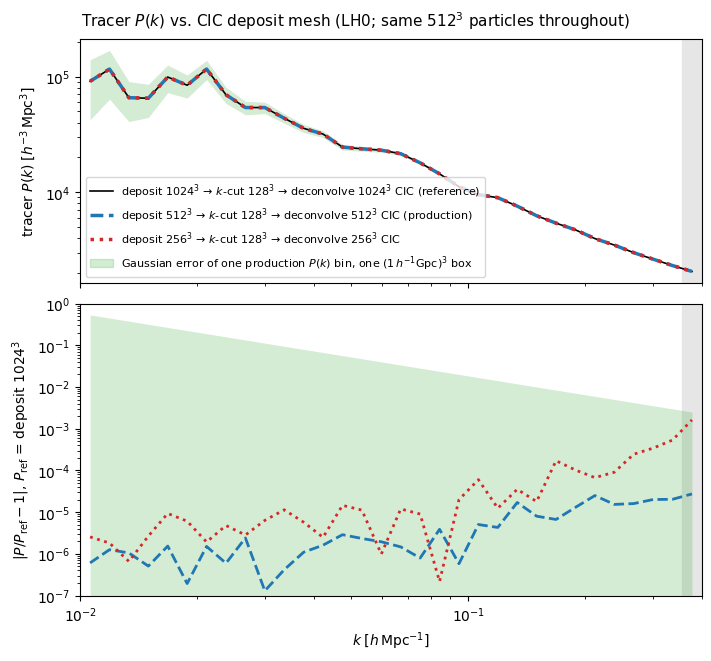

In [24]:
# Colour and line style = deposit mesh, in both panels. Shaded green = Gaussian error of one bin in one box.
from matplotlib.patches import Patch

color_err = "C2"
fig, (ax_p, ax_r) = plt.subplots(2, 1, figsize=(7, 6.5), sharex=True,
                                 gridspec_kw=dict(height_ratios=[1, 1.2]), layout="constrained")
p_ref = res[f"pk_tracer_{ref}"]
ax_p.fill_between(k, p_ref * (1 - sigma_frac), p_ref * (1 + sigma_frac), color=color_err, alpha=0.2, lw=0)
for c in [ref] + cfgs:
    ax_p.plot(k, res[f"pk_tracer_{c}"], color=cfg_colors[c], ls=cfg_ls[c], lw=cfg_lw[c], label=cfg_labels[c])
ax_p.set_yscale("log")
ax_p.set_ylabel(r"tracer $P(k)\;[h^{-3}\,\mathrm{Mpc}^{3}]$")
handles, _ = ax_p.get_legend_handles_labels()
handles.append(Patch(color=color_err, alpha=0.2,
                     label=r"Gaussian error of one production $P(k)$ bin, one $(1\,h^{-1}\mathrm{Gpc})^3$ box"))
ax_p.legend(handles=handles, fontsize=8)

ax_r.fill_between(k, 1e-7, sigma_frac, color=color_err, alpha=0.2, lw=0)
for c in cfgs:
    ax_r.plot(k, resid("tracer", c), color=cfg_colors[c], ls=cfg_ls[c], lw=2)
ax_r.set_yscale("log")
ax_r.set_ylim(1e-7, 1)
ax_r.set_xlabel(r"$k\;[h\,\mathrm{Mpc}^{-1}]$")
ax_r.set_ylabel(r"$|P/P_\mathrm{ref}-1|$, $P_\mathrm{ref}$ = deposit $1024^3$")
for ax in (ax_p, ax_r):
    ax.axvspan(k_cut_edge, edges[-1], color="0.9", zorder=0)
    ax.set_xscale("log")
    ax.set_xlim(edges[0], edges[-1])
fig.suptitle(r"Tracer $P(k)$ vs. CIC deposit mesh (LH0; same $512^3$ particles throughout)", fontsize=11)
plt.show()

**Summary**
- **Operators (question 1): no aliasing.** The linear field is smoothed at $0.75\,h$/Mpc, so the quadratic operators built on the $512^3$ particle grid have no power above $1.5\,h$/Mpc, below its Nyquist frequency of $1.61\,h$/Mpc. Nothing wraps, which is stronger than Orszag's 2/3 rule.
- **Deposit (question 2): aliasing is negligible.** Depositing the same $512^3$ particles on a $1024^3$ mesh instead of the production $512^3$ mesh changes the tracer $P(k)$ by at most $3\times10^{-5}$ over the production bins with $k \le 0.37\,h$/Mpc (each operator: at most $1.5\times10^{-4}$). The Gaussian error of one bin in one box is at least $3\times10^{-3}$, about 100× larger.
- **Deconvolution: effectively exact.** Each mesh is deconvolved with its own CIC window, and the windows differ by several percent at our highest $k$. After deconvolution the $512^3$ and $1024^3$ results still agree to the level above, so the deconvolution removes the window exactly up to the aliasing.
- **The test is sensitive.** The coarser $256^3$ deposit is ~20× worse and grows with $k$, as aliasing should.
- **Caveat:** one mock (LH0, $\sigma_8 = 0.70$). Cosmologies with higher $\sigma_8$ have more small-scale power and will alias somewhat more.

## 2. Phase-matched muchisimocks vs. SHAMe

The SHAMe high-fidelity mock lives on the BACCO "Rings" paired-and-fixed run (Planck, $L=1024\,h^{-1}$Mpc, $3072^3$, phases $0$ and $\pi$). Using the Rings seed **$-406168$** (verified with `make_shame_matched_mock.py check_seed`: the $132^3$ linear field correlates with the SHAMe $z=0$ matter mesh at $r>0.98$ for $k<0.05$, both phases; seed $0$ gives $r\approx0$), we regenerated the muchisimocks bias-operator fields with **identical initial conditions**: `make_shame_matched_mock.py make --seed -406168` (box 1024, $524^3 \to 132^3$, fixed amplitude, `phase_type=1`). Output: `muchisimocks_lib_ood/shame_matched/phase{0,pi}_seed-406168/`.

Because both share the same phases, differences are free of sample variance and can be compared mode by mode. Real space throughout (the SHAMe meshes are real space). Checks:

- **(a) Matter:** map2map $O_1 = 1+\delta_m$ vs. the N-body matter mesh.
- **(b) Tracer, deterministic part:** $\delta_t^\mathrm{model} = \delta_m + b_1\delta + b_2\delta^2 + b_{s^2}s^2 + b_{\nabla^2}\nabla^2\delta$ with (i) the SHAMe biases `utils_model.bias_dict_shame` ($b_2$, $b_{s^2}$ ÷2, see the convention note below) and (ii) biases fit at field level to each SHAMe catalog ($k\le0.2$, least squares over modes), compared with $P_\mathrm{SHAMe} - 1/\bar n$.
- **(c) Stochasticity:** $P_\mathrm{err}(k) = P(\delta_\mathrm{SHAMe} - \delta_t^\mathrm{model})$ in units of Poisson $1/\bar n$; this is what our noise model has to describe.

P(k) here is a plain numpy FFT estimator with $\Delta k = k_f$ (so auto, cross and residual spectra are binned identically); it agrees with the stored bacco SHAMe $P(k)$ to $<1\%$ except in the first couple of (differently binned) $k$ bins.

In [5]:
import utils_model
import make_shame_matched_mock as msm

L_SH = msm.BOX_SIZE            # 1024
NG_SH = msm.N_GRID_TARGET      # 132
SEED_SH = -406168
dir_matched = paths.mocks_lib_ood_dir(msm.SUBDIR_OOD)
tags_shame = ['_nbar0.00011', '_nbar0.00022', '_nbar0.00054']
phases_sh = ['0', 'pi']
kmax_fit = 0.2

def _kgrid(n, L):
    kf = 2 * np.pi / L
    kx = np.fft.fftfreq(n, d=1. / n) * kf
    kz = np.fft.rfftfreq(n, d=1. / n) * kf
    return np.sqrt(kx[:, None, None]**2 + kx[None, :, None]**2 + kz[None, None, :]**2)

KMAG_SH = _kgrid(NG_SH, L_SH)
_edges = np.arange(0.5, NG_SH // 2) * 2 * np.pi / L_SH      # dk = k_f
k_sh = 0.5 * (_edges[1:] + _edges[:-1])
_idx = np.digitize(KMAG_SH.ravel(), _edges) - 1
_ok = (_idx >= 0) & (_idx < len(k_sh))
_w = np.full(KMAG_SH.shape, 2.0); _w[..., 0] = 1; _w[..., -1] = 1   # rfft half-plane weights
_w = _w.ravel()[_ok]
_nmode = np.bincount(_idx[_ok], _w, len(k_sh))

def ft_sh(field):
    return np.fft.rfftn(field - field.mean()) * (L_SH / NG_SH)**3

def pk_sh(fa, fb=None):
    fb = fa if fb is None else fb
    p = (fa * np.conj(fb)).real.ravel()[_ok] * _w
    return np.bincount(_idx[_ok], p, len(k_sh)) / _nmode / L_SH**3

def load_matched_ops(phase):
    fn = dir_matched / f'phase{phase}_seed{SEED_SH}' / f'bias_fields_eul_deconvolved_{SEED_SH}.npy'
    ops = np.load(fn).astype(np.float64)
    return ops / ops[0].mean()     # O_1 -> 1 + delta_m; same factor for all operators (= get_tracer_field with n_grid_norm=524)

def load_shame_fields(phase, tag):
    tracer = np.load(msm.DIR_DATA_SHAME / f'data{tag}' / f'tracer_field_phase{phase}.npy') * NG_SH**3  # stored as delta/132^3
    dens = np.load(msm.DIR_DATA_SHAME / f'dens_mesh_phase{phase}.npy')
    return tracer, dens / dens.mean() - 1

def fit_bias_fieldlevel(ops_k, tk, kmax):
    m = (KMAG_SH <= kmax) & (KMAG_SH > 0)
    y = (tk - ops_k[0])[m]
    A = np.stack([o[m] for o in ops_k[1:]], axis=1)
    b, *_ = np.linalg.lstsq(np.concatenate([A.real, A.imag]), np.concatenate([y.real, y.imag]), rcond=None)
    return b

In [6]:
res_sh = {}
for phase in phases_sh:
    ops_k = [ft_sh(o) for o in load_matched_ops(phase)]
    _, dm = load_shame_fields(phase, tags_shame[0])
    dm_k = ft_sh(dm)
    p_m2m, p_nb = pk_sh(ops_k[0]), pk_sh(dm_k)
    res_sh[('matter', phase)] = dict(ratio=p_m2m / p_nb, r=pk_sh(ops_k[0], dm_k) / np.sqrt(p_m2m * p_nb))
    for tag in tags_shame:
        tk = ft_sh(load_shame_fields(phase, tag)[0])
        nbar = float(tag.split('nbar')[1])
        b_dict = np.array([utils_model.bias_dict_shame[tag][n] for n in utils_model.biasparam_names_ordered])
        b_fit = fit_bias_fieldlevel(ops_k, tk, kmax_fit)
        p_t = pk_sh(tk)
        out = dict(nbar=nbar, p_shame=p_t)
        for lab, b in [('dict', b_dict), ('fit', b_fit)]:
            mk = ops_k[0] + sum(bi * o for bi, o in zip(b, ops_k[1:]))
            p_m = pk_sh(mk)
            out[lab] = dict(b=b, p_model=p_m,
                            ratio_sn=(p_t - 1 / nbar) / p_m,
                            r=pk_sh(tk, mk) / np.sqrt(p_t * p_m),
                            perr_nbar=pk_sh(tk - mk) * nbar)
        res_sh[(tag, phase)] = out

# paired-fixed: average the two phases
def pmean(key, *sub):
    vals = []
    for ph in phases_sh:
        v = res_sh[(key, ph)]
        for s in sub:
            v = v[s]
        vals.append(v)
    return np.mean(vals, axis=0)

ksel = [0.05, 0.1, 0.2, 0.3, 0.35]
isel = [np.argmin(np.abs(k_sh - kk)) for kk in ksel]
print('k =', np.round(k_sh[isel], 3))
print(f"(a) matter  P_m2m/P_Nbody : {np.round(pmean('matter', 'ratio')[isel], 3)}   r : {np.round(pmean('matter', 'r')[isel], 3)}")
names = utils_model.biasparam_names_ordered
for tag in tags_shame:
    print(f'\n{tag}')
    for lab in ['dict', 'fit']:
        b = pmean(tag, lab, 'b')
        print(f"  [{lab:4s}] b = " + ", ".join(f'{n}={v:+.3f}' for n, v in zip(names, b)))
        print(f"         (P_shame-1/nbar)/P_model : {np.round(pmean(tag, lab, 'ratio_sn')[isel], 3)}")
        print(f"         r(shame, model)          : {np.round(pmean(tag, lab, 'r')[isel], 3)}")
        print(f"         P_err * nbar             : {np.round(pmean(tag, lab, 'perr_nbar')[isel], 3)}")

k = [0.049 0.098 0.202 0.301 0.35 ]
(a) matter  P_m2m/P_Nbody : [0.998 0.998 0.991 0.995 0.994]   r : [0.997 0.996 0.987 0.973 0.963]

_nbar0.00011
  [dict] b = b1=+0.529, b2=+0.069, bs2=-0.109, bl=-1.070
         (P_shame-1/nbar)/P_model : [0.941 0.93  0.901 0.801 0.788]
         r(shame, model)          : [0.875 0.785 0.641 0.555 0.523]
         P_err * nbar             : [0.967 0.966 0.972 0.97  0.978]
  [fit ] b = b1=+0.513, b2=+0.041, bs2=-0.078, bl=-0.293
         (P_shame-1/nbar)/P_model : [0.968 0.97  0.977 0.897 0.895]
         r(shame, model)          : [0.874 0.785 0.641 0.555 0.523]
         P_err * nbar             : [0.965 0.964 0.971 0.968 0.975]

_nbar0.00022
  [dict] b = b1=+0.474, b2=+0.032, bs2=-0.085, bl=-0.824
         (P_shame-1/nbar)/P_model : [0.95  0.932 0.936 0.86  0.831]
         r(shame, model)          : [0.924 0.862 0.748 0.663 0.629]
         P_err * nbar             : [0.996 0.973 0.969 0.978 0.984]
  [fit ] b = b1=+0.457, b2=+0.011, bs2=-0.068, bl=-0.23

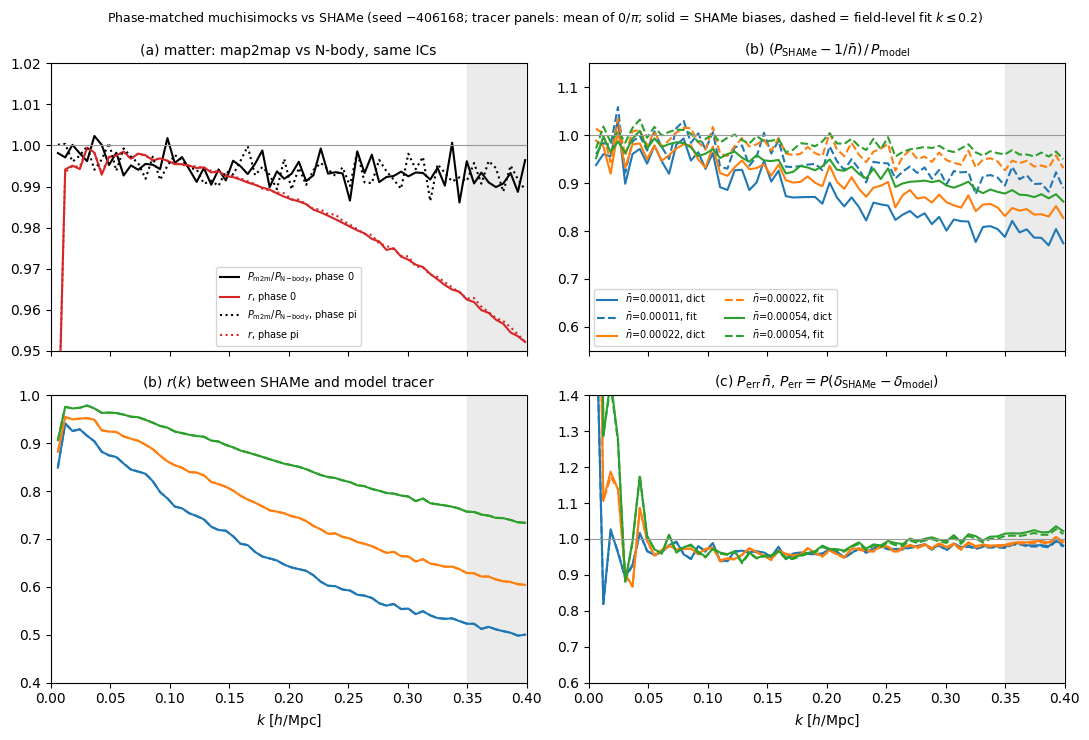

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), sharex=True)
ax_m, ax_p, ax_r, ax_e = axes.ravel()
colors_sh = dict(zip(tags_shame, ['C0', 'C1', 'C2']))
ls_lab = {'dict': '-', 'fit': '--'}

for ph, ls in zip(phases_sh, ['-', ':']):
    ax_m.plot(k_sh, res_sh[('matter', ph)]['ratio'], 'k', ls=ls, label=rf'$P_\mathrm{{m2m}}/P_\mathrm{{N\!-\!body}}$, phase {ph}')
    ax_m.plot(k_sh, res_sh[('matter', ph)]['r'], 'C3', ls=ls, label=rf'$r$, phase {ph}')
ax_m.axhline(1, color='0.6', lw=0.8)
ax_m.set_ylim(0.95, 1.02)
ax_m.set_title('(a) matter: map2map vs N-body, same ICs', fontsize=10)
ax_m.legend(fontsize=7)

for tag in tags_shame:
    c = colors_sh[tag]
    for lab in ['dict', 'fit']:
        kw = dict(color=c, ls=ls_lab[lab])
        ax_p.plot(k_sh, pmean(tag, lab, 'ratio_sn'), label=rf'$\bar n$={tag[5:]}, {lab}' , **kw)
        ax_r.plot(k_sh, pmean(tag, lab, 'r'), **kw)
        ax_e.plot(k_sh, pmean(tag, lab, 'perr_nbar'), **kw)
ax_p.axhline(1, color='0.6', lw=0.8)
ax_p.set_ylim(0.55, 1.15)
ax_p.set_title(r'(b) $(P_\mathrm{SHAMe} - 1/\bar n)\,/\,P_\mathrm{model}$', fontsize=10)
ax_p.legend(fontsize=7, ncol=2)
ax_r.set_title(r'(b) $r(k)$ between SHAMe and model tracer', fontsize=10)
ax_r.set_ylim(0.4, 1.0)
ax_e.axhline(1, color='0.6', lw=0.8)
ax_e.set_title(r'(c) $P_\mathrm{err}\,\bar n$, $P_\mathrm{err}=P(\delta_\mathrm{SHAMe}-\delta_\mathrm{model})$', fontsize=10)
ax_e.set_ylim(0.6, 1.4)
for ax in axes.ravel():
    ax.axvspan(kmax_analysis, k_sh.max(), color='0.92', zorder=0)
    ax.set_xlim(0, 0.4)
for ax in axes[1]:
    ax.set_xlabel(r'$k$ [$h$/Mpc]')
fig.suptitle(r'Phase-matched muchisimocks vs SHAMe (seed $-406168$; tracer panels: mean of $0/\pi$; solid = SHAMe biases, dashed = field-level fit $k\leq0.2$)', fontsize=9)
fig.tight_layout()
plt.show()

**Conclusions** (numbers are means over the $0/\pi$ pair, $k = 0.05 \to 0.35\,h$/Mpc):

- **(a) Matter.** With identical ICs, map2map reproduces the N-body matter $P(k)$ to $\lesssim1\%$ ($0.991$–$0.998$) over the whole range, and the fields agree mode by mode: $r = 0.997$ at $k=0.05$, $0.987$ at $0.2$, $0.963$ at $0.35$. The two phases agree, so this is not a fluke of one realization. The small decorrelation at high $k$ is map2map's own error (plus the $3072^3$ vs. $524^3$ particle resolution), and it is far below the tracer stochasticity below.
- **(b) Deterministic tracer.** With the **SHAMe** biases, the model has somewhat *too much* small-scale power: $(P_\mathrm{SHAMe}-1/\bar n)/P_\mathrm{model}$ drops from $0.94$–$0.97$ at $k=0.05$ to $0.79$ / $0.83$ / $0.88$ at $k=0.35$ for $\bar n = 1.1, 2.2, 5.4\times10^{-4}$. **Biases fit at field level** to the same catalogs ($k\le0.2$) bring it to within $\sim3\%$ up to $k=0.2$ and $4$–$10\%$ at $0.35$ ($0.90$ / $0.93$ / $0.96$). The fits agree with the SHAMe $b_1$ to $3$–$4\%$ and are close in $b_{s^2}$ ($-0.07$ vs $-0.05$ to $-0.11$), with slightly smaller $|b_2|$. Most of the remaining gap is $b_{\nabla^2}$: SHAMe $\approx-0.8$ vs field-level $\approx-0.25$. *Robustness (checked 2026-11-15, $k_\mathrm{max}^\mathrm{fit} = 0.1$–$0.3$):* $b_1, b_2, b_{s^2}$ are stable to $\lesssim0.03$ and agree between the two phases. $b_{\nabla^2}$ is **not** robust: it runs from $\approx-1$ to $-0.2$ with $k_\mathrm{max}$ and differs between phases by up to $0.2$–$1$, so the SHAMe $-0.8$ is not clearly excluded. Neither affects the inference, where the biases are free. $r(k)$ between SHAMe and model is the same for both bias sets ($0.52$–$0.76$ at $k=0.35$), because it is set by shot noise, not by the bias values.
- **(c) Stochasticity.** The residual $P_\mathrm{err} = P(\delta_\mathrm{SHAMe} - \delta_\mathrm{model})$ is **Poisson to a few percent**: $P_\mathrm{err}\bar n = 0.95$–$1.01$ for $k\gtrsim0.05$, for all three densities and both bias sets (slightly sub-Poisson, $\approx0.97$, around $k\sim0.1$–$0.2$; the $k<0.05$ excursions are few-mode noise). So, once sample variance is removed, SHAMe's stochastic part is close to white shot noise with amplitude $1/\bar n$. That is a useful anchor for the noise-model amplitudes.

#### Bias convention: $b_2$, $b_{s^2}$ divided by 2

The SHAMe biases come from the probabilistic Lagrangian estimators of Stücker et al. 2024 (arXiv:2405.01950), which write $F = 1 + b_1\delta + \tfrac12 b_2\delta^2 + \dots$. Our (bacco) operators are $\delta^2$ and $s^2$ with no $\tfrac12$, so `utils_model.bias_dict_shame` stores the delivered $b_2$ and $b_{s^2}$ **divided by 2** (confirmed with the person who measured them, 2026-11-15). All "SHAMe biases" in this notebook use this convention.

(Before 2026-11-15 the code multiplied them by 2 instead. The phase-matched tests below were what flagged it: the ×2 values gave too much small-scale power, e.g. a cross ratio $P_{\mathrm{SHAMe}\times\mathrm{model}}/P_\mathrm{model}$ of 0.86 vs 0.92 for ÷2 at $k=0.35$, $\bar n=2.2\times10^{-4}$, and a $P_{gm}$ reduced $\chi^2$ of 17.5 vs 4.4 in §2.5.)


### 2.1 Grids and box size

Everything in this comparison uses **box $L = 1024\,h^{-1}$Mpc**, the SHAMe/Rings box. It has to: the phases are only identical mode by mode if the Fourier grid ($k_f = 2\pi/1024$) is the same as the simulation's.

| | deposit grid | cell [$h^{-1}$Mpc] | target grid (k-cut) | cell [$h^{-1}$Mpc] | $k_N$ of target [$h$/Mpc] |
|---|---|---|---|---|---|
| muchisimocks library ($L=1000$) | $512^3$ | 1.953 | $128^3$ | 7.813 | 0.402 |
| matched muchisimocks ($L=1024$) | $524^3$ | 1.954 | $132^3$ | 7.758 | 0.405 |
| SHAMe tracer & matter ($L=1024$) | $524^3$ | 1.954 | $132^3$ | 7.758 | 0.405 |

- **matched vs. SHAMe:** identical grids, identical pipeline (CIC deposit on $524^3$ → $k$-cut to $132^3$ → CIC deconvolution, `process_mock_catalogs.py`), so the fields can be compared cell by cell.
- **matched vs. library:** the deposit cell (map2map's operating scale) matches to $0.07\%$. The target cell is $0.7\%$ smaller because $1024/7.8125 = 131.07$ is rounded to the nearest even integer (`round_to_nearest_even`). That only moves the $k$-cut/Nyquist from $0.402$ to $0.405\,h$/Mpc, above our $k_\mathrm{max}=0.35$. All statistics are binned in physical $k$ with the same edges ($0.01$–$0.4$), so the data vectors line up.
- Particle resolution is the one thing that does not match: map2map moves $524^3$ particles, the Rings run has $3072^3$.

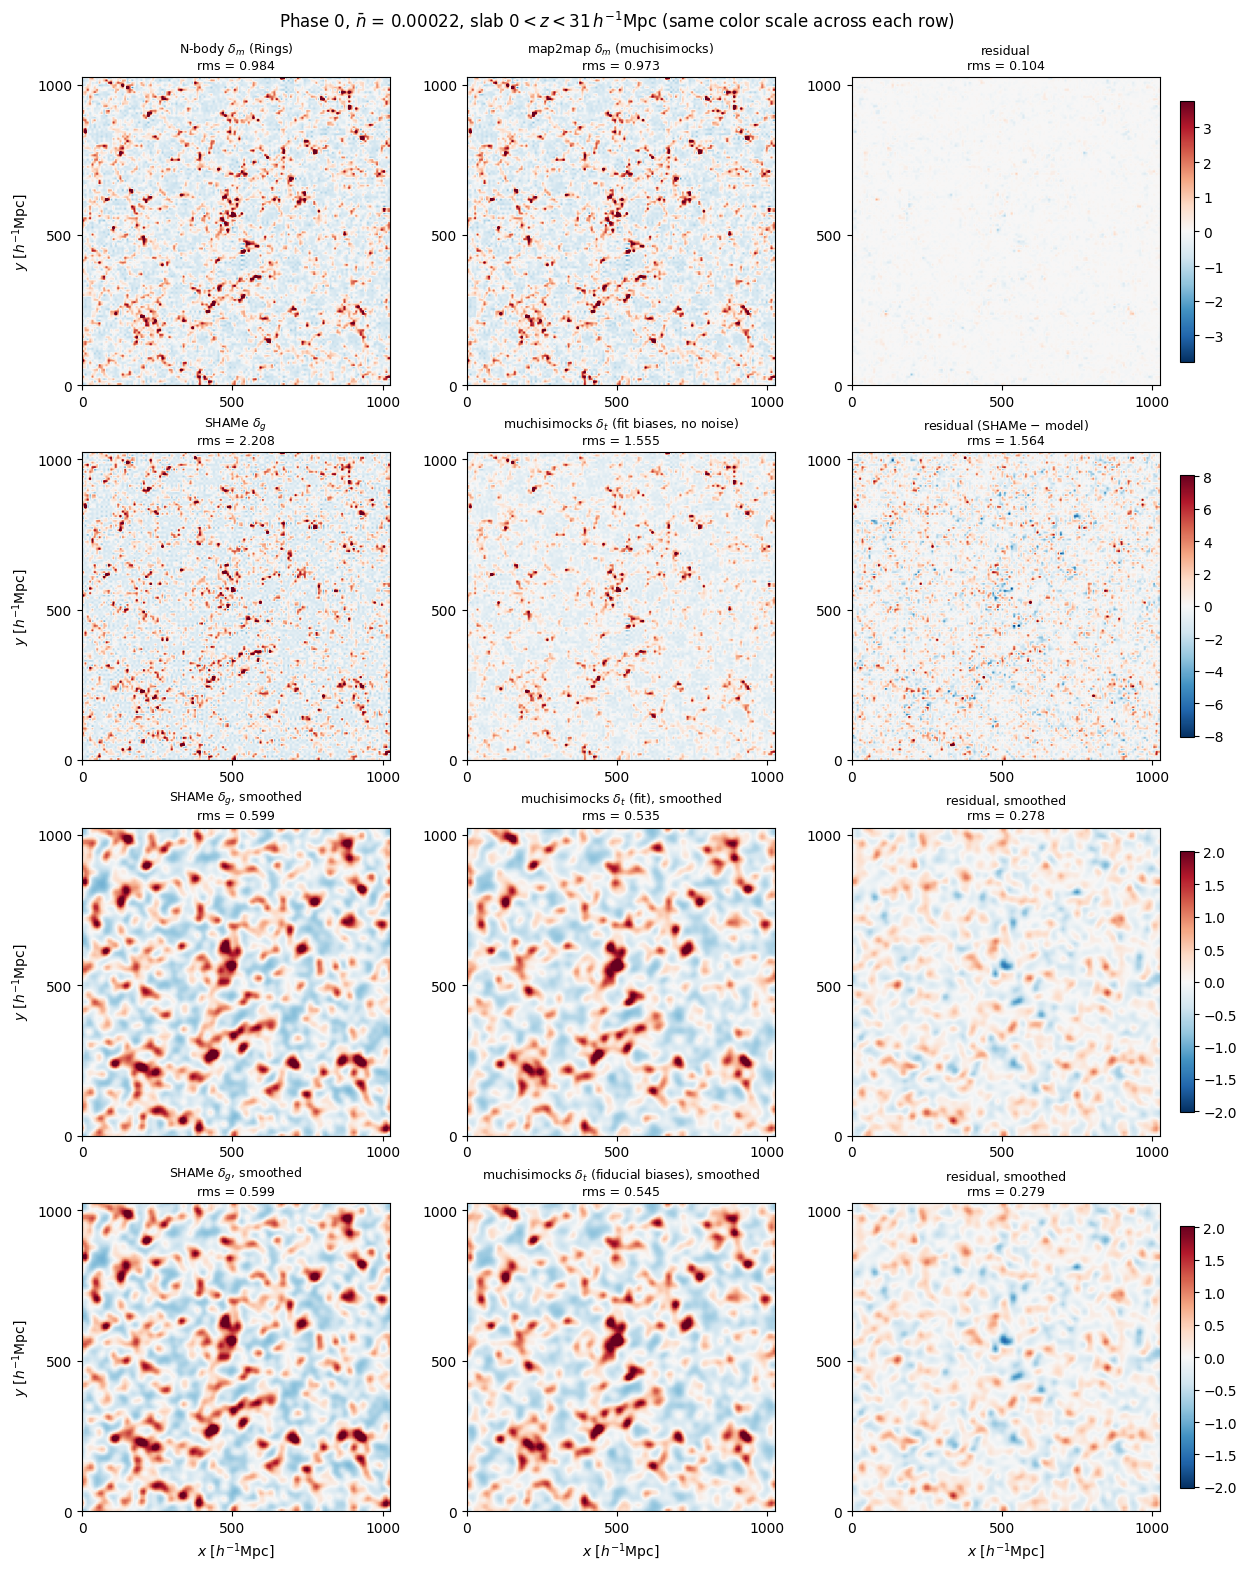

In [8]:
from scipy.ndimage import gaussian_filter

phase_show, tag_show = '0', '_nbar0.00022'
nslab = 4                                  # slab thickness in cells (4 x 7.76 = 31 Mpc/h)
R_smooth = 10.0                            # h^-1 Mpc, for the smoothed tracer row
cell = L_SH / NG_SH

ops_show = load_matched_ops(phase_show)
t_shame, dm_nbody = load_shame_fields(phase_show, tag_show)
b_fit_show = res_sh[(tag_show, phase_show)]['fit']['b']
b_dict_show = res_sh[(tag_show, phase_show)]['dict']['b']
dm_m2m = ops_show[0] - 1
t_model = dm_m2m + sum(b * o for b, o in zip(b_fit_show, ops_show[1:]))
t_model_dict = dm_m2m + sum(b * o for b, o in zip(b_dict_show, ops_show[1:]))

def slab(f):
    return f[:, :, :nslab].mean(axis=-1)

sm = lambda f: gaussian_filter(f, R_smooth / cell, mode='wrap')
rows = [
    ('matter', [r'N-body $\delta_m$ (Rings)', r'map2map $\delta_m$ (muchisimocks)', 'residual'],
     [dm_nbody, dm_m2m, dm_m2m - dm_nbody]),
    ('tracer', [r'SHAMe $\delta_g$', r'muchisimocks $\delta_t$ (fit biases, no noise)', 'residual (SHAMe $-$ model)'],
     [t_shame, t_model, t_shame - t_model]),
    (f'tracer, $R={R_smooth:.0f}$', [rf'SHAMe $\delta_g$, smoothed', rf'muchisimocks $\delta_t$ (fit), smoothed', 'residual, smoothed'],
     [sm(t_shame), sm(t_model), sm(t_shame - t_model)]),
    (f'tracer, $R={R_smooth:.0f}$, dict', [rf'SHAMe $\delta_g$, smoothed', rf'muchisimocks $\delta_t$ (SHAMe biases), smoothed', 'residual, smoothed'],
     [sm(t_shame), sm(t_model_dict), sm(t_shame - t_model_dict)]),
]
fig, axes = plt.subplots(len(rows), 3, figsize=(12.5, 3.9 * len(rows)), layout='constrained')
ext = [0, L_SH, 0, L_SH]
for (rowname, titles, fs), axrow in zip(rows, axes):
    vmax = np.percentile(np.abs(slab(fs[0])), 99)
    for f, ttl, ax in zip(fs, titles, axrow):
        im = ax.imshow(slab(f).T, origin='lower', extent=ext, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
        ax.set_title(ttl + f'\nrms = {slab(f).std():.3f}', fontsize=9)
        ax.set_xticks([0, 500, 1000]); ax.set_yticks([0, 500, 1000])
    fig.colorbar(im, ax=axrow, shrink=0.85, pad=0.01)
    axrow[0].set_ylabel(r'$y$ [$h^{-1}$Mpc]')
for ax in axes[-1]:
    ax.set_xlabel(r'$x$ [$h^{-1}$Mpc]')
fig.suptitle(rf'Phase {phase_show}, $\bar n$ = {tag_show[5:]}, slab $0<z<{nslab * cell:.0f}\,h^{{-1}}$Mpc (same color scale across each row)')
plt.show()

### 2.2 Summary statistics: $P(k)$, $P_{gm}(k)$, $B(k_1,k_2,k_3)$

All computed with the production estimators and binning (`compute_statistics.compute_pk` / `compute_pgm`, PolyBin3D `Bk_ideal` monopole; box 1024, $132^3$) by `code/compute_shame_matched_stats.py` (Slurm: `job_shame_matched_stats.s`). The SHAMe curves are the stored data vectors (`data/data_shame/data{nbar}_phase{0,pi}/`). Everything is averaged over the $0/\pi$ pair; $B$ is in physical units ($\times\,132^9$, as `data_loader.load_bispec` does).

**What is compared.** The muchisimocks tracer is deterministic (field-level-fit biases, and SHAMe biases, `bias_dict_shame`), plus the shot noise it **would** have if Poisson-sampled at the SHAMe density:
$$P^\mathrm{model} + \frac{1}{\bar n}, \qquad B^\mathrm{model} + \frac{P^\mathrm{model}_1+P^\mathrm{model}_2+P^\mathrm{model}_3}{\bar n} + \frac{1}{\bar n^2},$$
against the **raw** SHAMe statistics. $P_i$ are evaluated at the triangle's bin centers. Dotted curves are the deterministic model without the shot-noise terms. $P_{gm}$ has no shot noise.
I checked the units and the shot-noise normalization with a Poisson random catalog run through the same deposit → $k$-cut → deconvolve → estimator chain: $P\bar n = 1.00$, and `Bk_ideal` $= \bar n^{-2}/132^9$ (median over triangles).

*Why not subtract shot noise from SHAMe instead:* with Poisson subtraction, SHAMe's $B$ goes **negative** for high-$k$ triangles. SHAMe's 3-point stochasticity is strongly **sub-Poisson**, even though its 2-point residual is Poisson to $\sim3\%$ (§2c), so the ratio would be meaningless there.

$P_{gm}$ is always taken against the **N-body** matter mesh, the same field the SHAMe $P_{gm}$ uses. The dash-dot curve is what the **v1 production pipeline** computed for muchisimocks, with the $\delta$ operator (`bias_terms_eul[1]`) as "matter". v2 uses the '1' operator instead (fixed 2026-11-15).

(The stats file also has variants with a toy multiplicative noise $(1+\delta_m)A\epsilon$ at the Poisson level. They aren't the paper's noise model, so they're left out here.)

Residuals are model / SHAMe $- 1$. The grey band is the per-bin Gaussian error of SHAMe $P$ for one box, for scale only. With matched phases the scatter is much smaller, except at the lowest $k$, where SHAMe's own shot-noise realization is not matched.

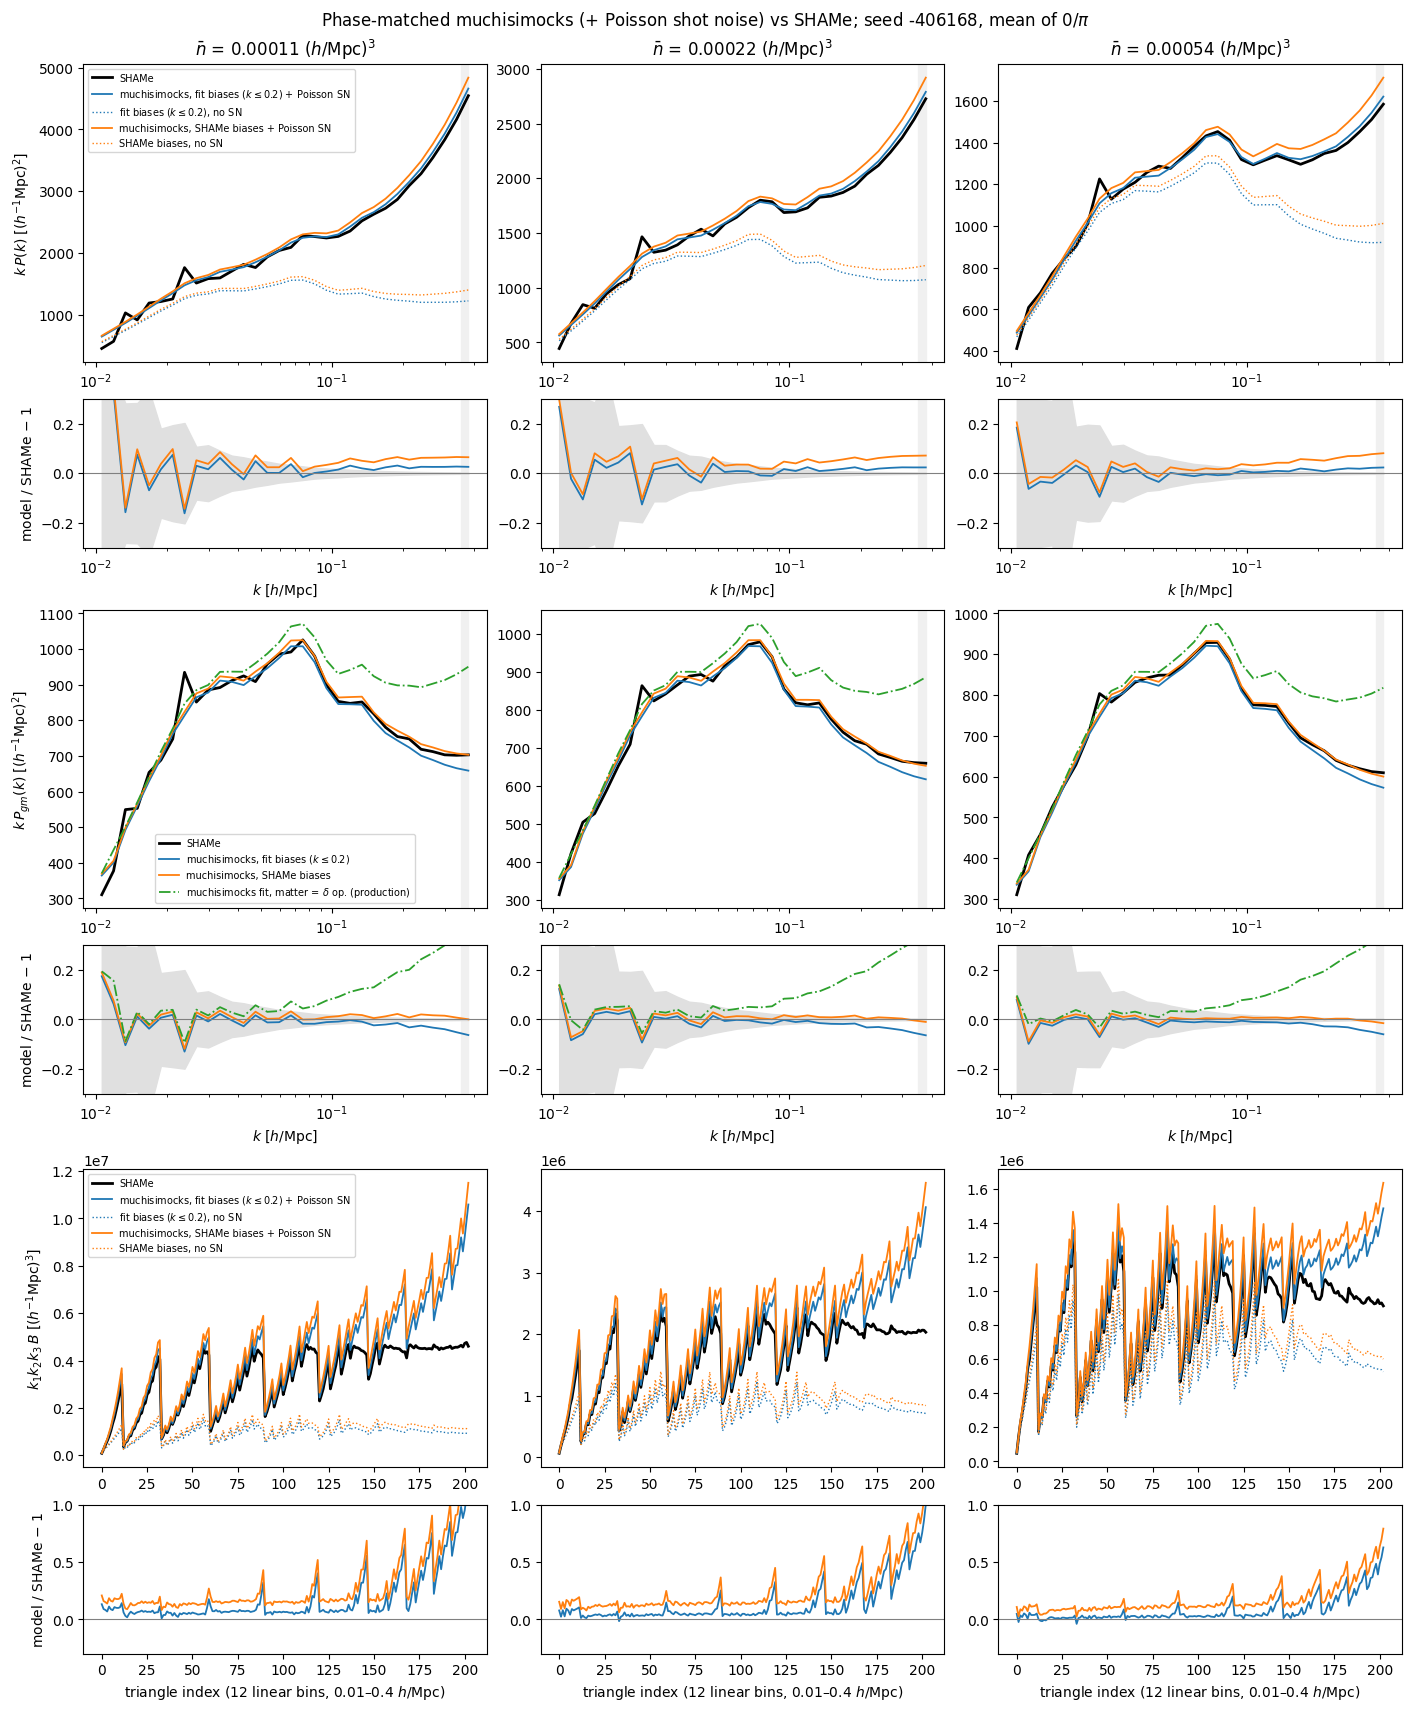

|model / SHAMe - 1|, median / max   (P, Pgm: 0.03 <= k <= 0.35;  B: all 203 triangles)
                                              _nbar0.00011                        _nbar0.00022                        _nbar0.00054
                                 P         Pgm           B           P         Pgm           B           P         Pgm           B
fit biases ($k         0.024/0.062 0.017/0.052 0.074/1.300 0.016/0.038 0.017/0.054 0.052/1.001 0.009/0.035 0.012/0.050 0.034/0.627
SHAMe biases           0.055/0.085 0.013/0.035 0.162/1.499 0.048/0.070 0.009/0.029 0.151/1.196 0.036/0.077 0.005/0.019 0.121/0.792
fit, Pgm vs delta op             - 0.090/0.324           -           - 0.086/0.314           -           - 0.084/0.312           -


In [9]:
stats_m = np.load(msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'stats.npy', allow_pickle=True).item()
B_NORM = float(NG_SH)**9            # PolyBin Bk_ideal on delta/N^3 fields -> physical (load_bispec convention)
k123_st = stats_m['k123']
wB = stats_m['weight']
itri = np.arange(len(wB))
k_st = stats_m[(tags_shame[0], '0')]['k']

def shame_raw(tag, stat):
    vals = []
    for ph in phases_sh:
        d = np.load(msm.DIR_DATA_SHAME / f'data{tag}_phase{ph}' / f'{stat}s' / f'{stat}.npy', allow_pickle=True).item()
        vals.append(d['bispectrum']['b0'] * B_NORM if stat == 'bispec' else d['pk'])
        err = None if stat == 'bispec' else d['pk_gaussian_error']
    return np.mean(vals, axis=0), err

def model_det(tag, var, stat, matter='nbody'):
    vals = []
    for ph in phases_sh:
        r = stats_m[(tag, ph)][var]
        vals.append({'pk': r['pk'], 'pgm': r['pgm'][matter], 'bispec': r['bk'] * B_NORM}[stat])
    return np.mean(vals, axis=0)

def model_obs(tag, var, stat, matter='nbody'):
    # deterministic model + the shot noise it would have if Poisson-sampled at nbar
    nbar = float(tag.split('nbar')[1])
    det = model_det(tag, var, stat, matter)
    if stat == 'pk':
        return det + 1 / nbar
    if stat == 'pgm':
        return det
    p_i = np.exp(np.interp(np.log(k123_st), np.log(k_st), np.log(model_det(tag, var, 'pk'))))   # (3, ntri)
    return det + p_i.sum(axis=0) / nbar + 1 / nbar**2

variants = [('fit', 'C0', rf'muchisimocks, fit biases ($k\leq{kmax_fit}$)'),
            ('dict', 'C1', 'muchisimocks, SHAMe biases')]
stat_labels = {'pk': r'$k\,P(k)$ [$(h^{-1}$Mpc$)^2$]', 'pgm': r'$k\,P_{gm}(k)$ [$(h^{-1}$Mpc$)^2$]',
               'bispec': r'$k_1k_2k_3\,B$ [$(h^{-1}$Mpc$)^3$]'}

fig, axes = plt.subplots(6, 3, figsize=(14, 17), sharex='row',
                         gridspec_kw=dict(height_ratios=[2, 1, 2, 1, 2, 1]), layout='constrained')
for j, tag in enumerate(tags_shame):
    for irow, stat in enumerate(['pk', 'pgm', 'bispec']):
        ax, axr = axes[2 * irow, j], axes[2 * irow + 1, j]
        sh, err = shame_raw(tag, stat)
        x = itri if stat == 'bispec' else k_st
        scale = wB if stat == 'bispec' else k_st
        ax.plot(x, scale * sh, 'k', lw=2, label='SHAMe')
        for var, c, lab in variants:
            m = model_obs(tag, var, stat)
            ax.plot(x, scale * m, color=c, lw=1.3, label=lab + ('' if stat == 'pgm' else ' + Poisson SN'))
            if stat != 'pgm':
                ax.plot(x, scale * model_det(tag, var, stat), color=c, ls=':', lw=1, label=lab.replace('muchisimocks, ', '') + ', no SN')
            axr.plot(x, m / sh - 1, color=c, lw=1.3)
        if stat == 'pgm':
            m = model_obs(tag, 'fit', stat, matter='O1')
            ax.plot(x, scale * m, color='C2', ls='-.', lw=1.3, label=r'muchisimocks fit, matter = $\delta$ op. (production)')
            axr.plot(x, m / sh - 1, color='C2', ls='-.', lw=1.3)
        if err is not None:
            axr.fill_between(x, -err / sh, err / sh, color='0.88', zorder=0)
            for a in (ax, axr):
                a.axvspan(kmax_analysis, x.max(), color='0.94', zorder=-1)
                a.set_xscale('log')
        axr.axhline(0, color='0.5', lw=0.8)
        axr.set_ylim(*((-0.3, 1.0) if stat == 'bispec' else (-0.3, 0.3)))
        if j == 0:
            ax.set_ylabel(stat_labels[stat]); axr.set_ylabel('model / SHAMe $-$ 1')
            ax.legend(fontsize=7)
        if irow == 0:
            ax.set_title(rf'$\bar n$ = {tag[5:]} $(h/\mathrm{{Mpc}})^3$')
        axr.set_xlabel('triangle index (12 linear bins, 0.01–0.4 $h$/Mpc)' if stat == 'bispec' else r'$k$ [$h$/Mpc]')
fig.suptitle(f'Phase-matched muchisimocks (+ Poisson shot noise) vs SHAMe; seed {SEED_SH}, mean of $0/\\pi$')
plt.show()

# Summary: median and max |residual|; P, Pgm over 0.03 <= k <= kmax_analysis (lowest bins are SHAMe shot-noise-dominated scatter)
mk = (k_st >= 0.03) & (k_st <= kmax_analysis)
print(f'|model / SHAMe - 1|, median / max   (P, Pgm: {0.03} <= k <= {kmax_analysis};  B: all {len(wB)} triangles)')
print(f"{'':22s}" + ''.join(f'{t:>36s}' for t in tags_shame))
print(f"{'':22s}" + ''.join(f"{'P':>12s}{'Pgm':>12s}{'B':>12s}" for _ in tags_shame))
rows = [(v, lab.split(',')[1].strip()[:14], 'nbody') for v, _, lab in variants] + [('fit', 'fit, Pgm vs delta op', 'O1')]
for var, lab, matter in rows:
    line = ''
    for tag in tags_shame:
        for stat in ['pk', 'pgm', 'bispec']:
            if matter == 'O1' and stat != 'pgm':
                line += f"{'-':>12s}"; continue
            r = np.abs(model_obs(tag, var, stat, matter) / shame_raw(tag, stat)[0] - 1)
            r = r if stat == 'bispec' else r[mk]
            line += f'{np.median(r):6.3f}/{r.max():5.3f}'
    print(f'{lab:22s}{line}')

**Conclusions, §2.2** ($P$, $P_{gm}$ over $0.03\le k\le0.35$; median / max of $|\mathrm{model}/\mathrm{SHAMe}-1|$; model = deterministic + Poisson shot noise):

| $\bar n$ | biases | $P$ | $P_{gm}$ | $B$ (all 203 triangles) | $P_{gm}$, $\delta$ op. as matter (v1) |
|---|---|---|---|---|---|
| $1.1\times10^{-4}$ | fit | 2.4% / 6% | 1.7% / 5% | 7% / 130% | 9% / 32% |
| | SHAMe | 5.5% / 8.5% | 1.3% / 3.5% | 16% / 150% | |
| $2.2\times10^{-4}$ | fit | 1.6% / 4% | 1.7% / 5% | 5% / 100% | 9% / 31% |
| | SHAMe | 4.8% / 7% | 0.9% / 2.9% | 15% / 120% | |
| $5.4\times10^{-4}$ | fit | 0.9% / 3.5% | 1.2% / 5% | 3% / 63% | 8% / 31% |
| | SHAMe | 3.6% / 7.7% | 0.5% / 1.9% | 12% / 79% | |

- **$P$ and $P_{gm}$:** with matched phases, the muchisimocks bias model (+ Poisson shot noise) reproduces SHAMe to a few percent over the whole analysis range. The SHAMe biases give $P$ $5$–$8\%$ high at $k=0.35$ (too much deterministic power, §2b) but the best $P_{gm}$ (≤3.5% everywhere). The field-level fit runs $\sim5\%$ low in $P_{gm}$ at $k\to0.35$. The lowest-$k$ bins scatter by $\sim10$–$20\%$ because SHAMe's own shot-noise realization isn't matched.
- **$B$:** the deterministic model is right at low $k$, but **Poisson** shot noise overshoots SHAMe for triangles with large $k_i$, by up to a factor ~2 at $k_i \sim 0.4$. SHAMe's 3-point stochasticity is strongly sub-Poisson there (Poisson-subtracted SHAMe $B$ goes negative), even though its 2-point stochasticity is Poisson to 3%. So a Poisson-level noise model gets $B$ wrong; §2.3–2.4 show that the fitted multiplicative noise model gets it right.
- **$P_{gm}$ matter field (fixed in v2):** v1 muchisimocks used `bias_terms_eul[1]` (the advected $\delta$ operator) as the matter field, while the SHAMe data vector uses the true N-body matter. On identical ICs, these differ by $8$–$9\%$ (median) and **~31% at $k=0.35$**. Compared like for like (N-body or map2map $O_1$ matter), the agreement is 1–2%. v2 uses the '1' operator.


### 2.3 Populated like the cosmic-variance set: SHAMe biases + best-fit noise

This is the paper's configuration for the fixed-SHAMe-cosmology test set (`_shame_p0_n1000`, scenario `noisy` in `generate_config_inference._TEST_SCENARIO_TAGS`), applied to the matched mock: `tag_biasparams = _biasshame_noisebest_p0_n1`, i.e. the measured SHAMe biases for $\bar n = 2.2\times10^{-4}$ (same values as `bias_dict_shame['_nbar0.00022']`, the "SHAMe biases" curves above) plus the best-fit multiplicative noise amplitudes from §2.5 (fit with these biases fixed) $(A_\mathrm{homog}, A_{b_1}, A_{b_2}, A_{b_{s^2}}, A_{b_\nabla})$ on unit Gaussian noise fields, built with `utils_model.get_tracer_field(..., noise_model='multiplicative')` exactly as `compute_statistics.make_tracer_field` does. Script: `code/compute_shame_matched_noisebest.py` (Slurm `job_shame_matched_noisebest.s`).

Because of the matched grid, two things differ from the library: the unit noise fields are drawn fresh at $132^3$ (10 realizations, the same seed for both phases of a pair), and **all five** noise amplitudes $A$ are multiplied by $(V_\mathrm{cell,lib}/V_\mathrm{cell,matched})^{1/2} = 1.011$. Why: a unit-variance white field $\epsilon$ on a grid has $P_\epsilon(k) = V_\mathrm{cell}$, so the noise term $A\,\epsilon\,O_i$ has power $\propto A^2 V_\mathrm{cell}$. The matched cells ($1024/132 = 7.758\,h^{-1}$Mpc) are $2.1\%$ smaller in volume than the library's ($1000/128 = 7.8125$), so the same $A$ would give $2.1\%$ less physical noise power; scaling $A$ by $\sqrt{1.021}$ restores it. The purple curve uses the library $A$ unchanged (`compute_shame_matched_noisebest.py --no-rescale`) to show how much this matters.

The noise is not phase-matched to SHAMe's own stochasticity, so the band shows the 16–84% spread over the 10 noise realizations (each one a $0/\pi$ pair mean). The deterministic part is still free of cosmic variance. **Curves:**
- **black, thick:** SHAMe $\bar n = 2.2\times10^{-4}$, raw statistics (shot noise included), mean of the $0/\pi$ pair.
- **red solid + band:** matched muchisimocks, SHAMe biases + best-fit multiplicative noise with rescaled $A$ (the CV-set configuration). Line = median of the 10 noise realizations, band = 16–84%.
- **purple solid + band** ($P$, $B$ only): the same, but with $A$ **not** rescaled. Not shown for $P_{gm}$ because the noise is uncorrelated with matter, so it can't change $P_{gm}$.
- **blue dashed** ($P_{gm}$ only): the same tracer field as red solid, cross-correlated with map2map's own nonlinear matter, $\mathcal{O}_1$ (bias field 0, the '1' operator), instead of the N-body mesh. This is the matter field the library mocks *should* use, since they have no N-body run.
- **red dash-dot** ($P_{gm}$ only): the same tracer field as red solid, but the "matter" it is cross-correlated with is the $\delta$ operator, not the N-body matter mesh. This is what the v1 production pipeline computed for every muchisimocks mock (`bias_terms_eul[1]`; v2 uses the '1' operator). The $\delta$ operator is the *linear* field $\delta_L$ carried to the map2map positions, so it is missing the nonlinear growth of the true matter field. SHAMe's stored $P_{gm}$ uses the N-body matter. The gap between red solid and red dash-dot is therefore the size of that v1 inconsistency (§2.2), not a bias/noise model error.
- **orange dashed:** SHAMe biases, no noise field, plus analytic Poisson shot noise for $P$ and $B$ (none for $P_{gm}$), as in §2.2.

_biasshame_noisebest_p0_n1: b = [ 0.4741  0.0318 -0.0847 -0.8244]
A_noise (x1.0106) = [ 2.0365 -1.9765  0.9942 -0.6794 -8.2436],  n_real = 10
no-rescale check: A_noise (x1.0000) = [ 2.0151 -1.9557  0.9838 -0.6722 -8.1568]


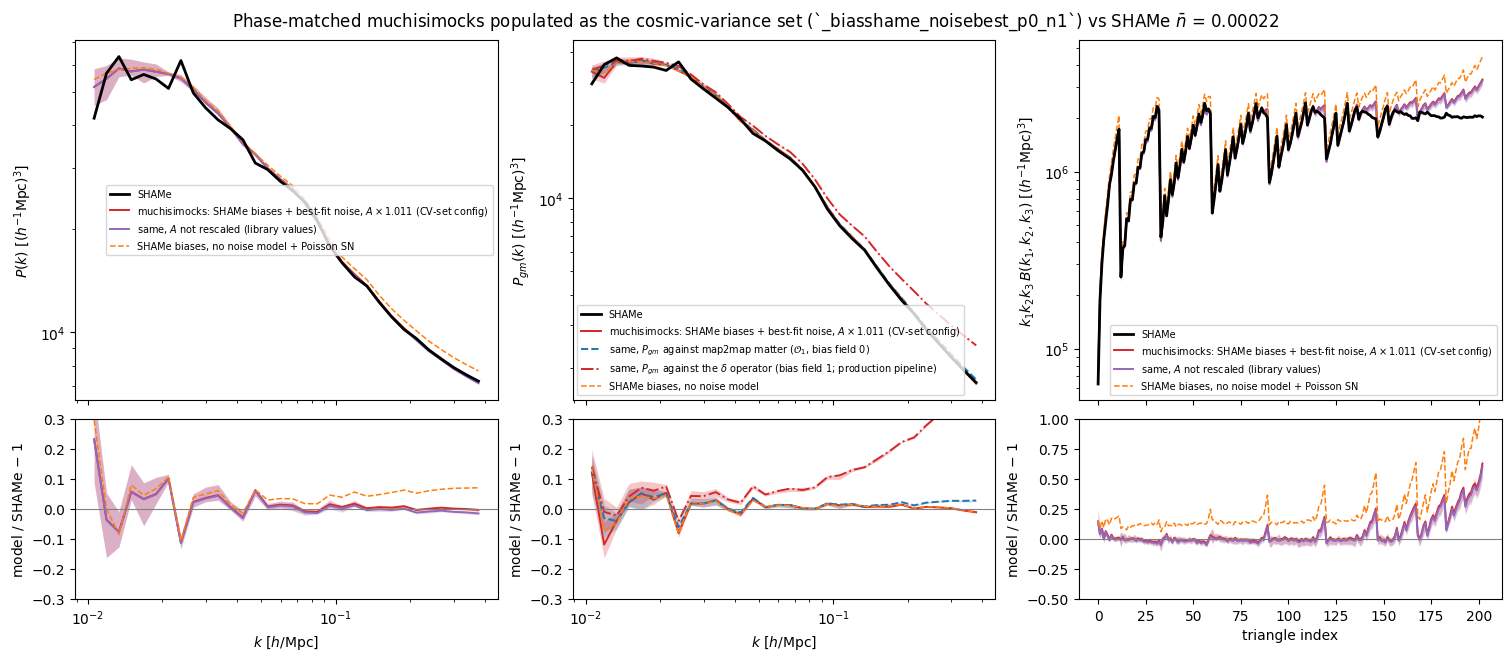

|model / SHAMe - 1| (median over noise realizations of: median / max over bins; P, Pgm: 0.03 <= k <= 0.35; B: all triangles)
  P              0.008 / 0.069
  Pgm            0.009 / 0.038
  Pgm, m2m O_1   0.015 / 0.040
  Pgm, delta op  0.114 / 0.385
  B              0.028 / 0.629
P ratio at k = [0.1, 0.2, 0.3, 0.35] : [1.016 1.01  1.001 1.   ]


In [10]:
nb_stats = np.load(msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'stats_noisebest.npy', allow_pickle=True).item()
tag_nb = nb_stats['tag_mock']
print(f"{nb_stats['tag_biasparams']}: b = {np.round(nb_stats['b'], 4)}")
print(f"A_noise (x{nb_stats['V_scale']:.4f}) = {np.round(nb_stats['A_noise'], 4)},  n_real = {nb_stats['n_real']}")

fn_norescale = msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'stats_noisebest_norescale.npy'
nb_stats_norescale = np.load(fn_norescale, allow_pickle=True).item() if fn_norescale.exists() else None
if nb_stats_norescale is not None:
    print(f"no-rescale check: A_noise (x{nb_stats_norescale['V_scale']:.4f}) = {np.round(nb_stats_norescale['A_noise'], 4)}")

def nb_real(stat, matter='nbody', st=None):
    # (n_real, nbins): pair mean for each noise realization
    st = nb_stats if st is None else st
    get = {'pk': lambda d: d['pk'], 'pgm': lambda d: d['pgm'][matter], 'bispec': lambda d: d['bk'] * B_NORM}[stat]
    return 0.5 * (get(st['0']) + get(st['pi']))

stat_labels_raw = {'pk': r'$P(k)$ [$(h^{-1}$Mpc$)^3$]', 'pgm': r'$P_{gm}(k)$ [$(h^{-1}$Mpc$)^3$]',
                   'bispec': r'$k_1k_2k_3\,B(k_1,k_2,k_3)$ [$(h^{-1}$Mpc$)^3$]'}

fig, axes = plt.subplots(2, 3, figsize=(15, 6.5), sharex='col',
                         gridspec_kw=dict(height_ratios=[2, 1]), layout='constrained')
for j, stat in enumerate(['pk', 'pgm', 'bispec']):
    ax, axr = axes[0, j], axes[1, j]
    sh, err = shame_raw(tag_nb, stat)
    x = itri if stat == 'bispec' else k_st
    scale = wB if stat == 'bispec' else 1.0     # B always shown as k1 k2 k3 B (the data vector)
    ax.plot(x, scale * sh, 'k', lw=2, label='SHAMe', zorder=5)
    curves = [(nb_real(stat), 'C3', '-', r'muchisimocks: SHAMe biases + best-fit noise, $A\times1.011$ (CV-set config)')]
    if nb_stats_norescale is not None and stat != 'pgm':   # noise doesn't enter P_gm
        curves.append((nb_real(stat, st=nb_stats_norescale), 'C4', '-', r'same, $A$ not rescaled (library values)'))
    if stat == 'pgm':
        curves.append((nb_real(stat, 'm2m'), 'C0', '--', r'same, $P_{gm}$ against map2map matter ($\mathcal{O}_1$, bias field 0)'))
        curves.append((nb_real(stat, 'delta_op'), 'C3', '-.', r'same, $P_{gm}$ against the $\delta$ operator (bias field 1; production pipeline)'))
    for arr, c, ls, lab in curves:
        lo, med, hi = np.percentile(arr, [16, 50, 84], axis=0)
        ax.plot(x, scale * med, color=c, ls=ls, lw=1.4, label=lab)
        ax.fill_between(x, scale * lo, scale * hi, color=c, alpha=0.25, lw=0)
        axr.plot(x, med / sh - 1, color=c, ls=ls, lw=1.4)
        axr.fill_between(x, lo / sh - 1, hi / sh - 1, color=c, alpha=0.25, lw=0)
    m_ref = model_obs(tag_nb, 'dict', stat)
    ax.plot(x, scale * m_ref, color='C1', ls='--', lw=1.1, label='SHAMe biases, no noise model' + ('' if stat == 'pgm' else ' + Poisson SN'))
    axr.plot(x, m_ref / sh - 1, color='C1', ls='--', lw=1.1)
    if stat != 'bispec':
        for a in (ax, axr):
            a.set_xscale('log')
    axr.axhline(0, color='0.5', lw=0.8)
    axr.set_ylim(*((-0.5, 1.0) if stat == 'bispec' else (-0.3, 0.3)))
    ax.set_yscale('log')
    ax.set_ylabel(stat_labels_raw[stat]); axr.set_ylabel('model / SHAMe $-$ 1')
    axr.set_xlabel('triangle index' if stat == 'bispec' else r'$k$ [$h$/Mpc]')
    ax.legend(fontsize=7)
fig.suptitle(rf'Phase-matched muchisimocks populated as the cosmic-variance set (`{nb_stats["tag_biasparams"]}`) vs SHAMe $\bar n$ = {tag_nb[5:]}')
plt.show()

mk = (k_st >= 0.03) & (k_st <= kmax_analysis)
print(f'|model / SHAMe - 1| (median over noise realizations of: median / max over bins; P, Pgm: 0.03 <= k <= {kmax_analysis}; B: all triangles)')
for lab, stat, matter in [('P', 'pk', 'nbody'), ('Pgm', 'pgm', 'nbody'), ('Pgm, m2m O_1', 'pgm', 'm2m'), ('Pgm, delta op', 'pgm', 'delta_op'), ('B', 'bispec', 'nbody')]:
    r = np.abs(nb_real(stat, matter) / shame_raw(tag_nb, stat)[0] - 1)
    r = r if stat == 'bispec' else r[:, mk]
    print(f'  {lab:14s} {np.median(np.median(r, axis=1)):.3f} / {np.median(r.max(axis=1)):.3f}')
kk = [0.1, 0.2, 0.3, 0.35]
ik = [np.argmin(np.abs(k_st - q)) for q in kk]
print('P ratio at k =', kk, ':', np.round(np.median(nb_real('pk') / shame_raw(tag_nb, 'pk')[0], axis=0)[ik], 3))

**Conclusions, §2.3** (CV-set configuration `_biasshame_noisebest_p0_n1`, $\bar n = 2.2\times10^{-4}$; median over noise realizations of median / max $|\mathrm{model}/\mathrm{SHAMe}-1|$, $0.03\le k\le0.35$):

| | $P$ | $P_{gm}$ (N-body matter) | $P_{gm}$ (map2map $\mathcal{O}_1$, v2) | $P_{gm}$ ($\delta$ op., v1) | $B$ (all triangles) |
|---|---|---|---|---|---|
| SHAMe biases + best-fit noise | **0.8% / 6.9%** | **0.9% / 3.8%** | 1.5% / 4.0% | 11% / 39% | **2.8%** / 63% |
| SHAMe biases, Poisson SN only (§2.2) | 4.8% / 7% | 0.9% / 2.9% | – | – | 15% / 120% |

- **$P$:** with the best-fit noise, the CV-set configuration reproduces SHAMe's $P$ to $\sim1\%$ (ratio $1.016, 1.010, 1.001, 1.000$ at $k = 0.1, 0.2, 0.3, 0.35$). The max comes from the few lowest-$k$ bins, where SHAMe's shot-noise realization isn't matched. The noise model compensates for the excess deterministic power of these biases (§2b) by being sub-Poisson at high $k$. The spread over noise realizations is sub-percent.
- **$P_{gm}$:** noise doesn't enter $P_{gm}$ (it is uncorrelated with matter), so this is the deterministic result: ≲1% median, ≲4% max. Against map2map's $\mathcal{O}_1$ (what v2 uses) it is 1.5%, rising to $+3\%$ at $k=0.35$; with the v1 $\delta$-operator "matter" it was 11% median and ~40% at high $k$.
- **$B$:** now matches SHAMe to ≲3% for most triangles, compared with 15% for Poisson. The only large residuals are the highest-$k$ triangles ($k_i\gtrsim0.3$, beyond our $B$ cut of 0.25), which overshoot by up to $+30$–$60\%$, as every model does (§2.4). The $B$ undershoot this section used to show ($-10$ to $-30\%$) came from the old configuration (×2 biases + noise amplitudes picked on a cosmic-variance realization) and is gone with the ÷2 biases and the noise refit on the matched mock (§2.5).
- Not rescaling $A$ by 1.011 (purple) makes no visible difference.


### 2.4 Can an extra $\epsilon^2$ noise term fix $B$? (fit on the matched mock, no cosmic variance)

The old best-fit noise points (`noisebest` before 2026-11-15, `noisem2best`) were each picked as the best of 1000 library mocks that all have **different** initial conditions, so the pick partly selected a lucky cosmic-variance fluctuation. (`noisebest` is now refit on the matched mock instead, §2.5.) Here I refit the noise amplitudes directly on the phase-matched mock, where there is no cosmic variance to exploit, and ask which noise terms are needed to match SHAMe's $P$ and $B$ together.

**Setup** (coefficients: `code_auxiliary/compute_shame_matched_noisepoly.py`, Slurm `code_auxiliary/jobs/job_shame_matched_noisepoly.s`, ~45 min; fits: `code_auxiliary/fit_shame_matched_noisepoly.py`, ~1 min, run on a login node). $\bar n = 2.2\times10^{-4}$; biases fixed at the field-level fit (phase mean, §2b), so the deterministic part is as good as it gets. The tracer is linear in the noise amplitudes,
$$\delta_t = \delta_\mathrm{det} + \sum_{i=1}^{5} A_i\,\epsilon\,\mathcal{O}_i \;+\; A^{(2)}_{1}\,(\epsilon^2-1)\,\mathcal{O}_1 \;+\; A^{(2)}_{\nabla^2}\,(\epsilon^2-1)\,\mathcal{O}_{\nabla^2\delta},$$
so $P$ is exactly quadratic and $B$ exactly cubic in the $A$'s. The job computes those coefficients once (2 noise realizations × 2 phases; the cubic fit reproduces held-out $B$ evaluations to $10^{-13}$), and every fit below is then instant. I use $\epsilon^2-1$ rather than the production $\epsilon^2$: the mean part of $\epsilon^2$ only rescales the $\mathcal{O}_1$ term, which free biases would absorb anyway.

**Fit:** minimize $\langle(P/P_\mathrm{SHAMe}-1)^2\rangle_{0.03\le k\le0.35} + \langle(B/B_\mathrm{SHAMe}-1)^2\rangle_{k_i<0.25}$ (equal weight per probe, fractional residuals, 10 random L-BFGS starts; models containing the 5-param one also start from its solution), against the raw SHAMe $P$ and $B$ (all stochasticity comes from the noise terms, as in the library mocks). Triangles with $k_i \ge 0.25$ are not fit, so they show how well each model extrapolates.

Models compared: $\epsilon$ terms only (the paper's 5-parameter model), plus each $\epsilon^2$ term on its own, and the production m2p3 basis ($\epsilon\mathcal{O}_1$, $\epsilon^2\mathcal{O}_1$, $\epsilon^2\mathcal{O}_{\nabla^2\delta}$).


In [11]:
# Fits are done by code_auxiliary/fit_shame_matched_noisepoly.py (~1 min); this cell only loads them.
fits_np = np.load(msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'noise_poly_fits.npy', allow_pickle=True).item()
k_p, mP, mB, mB_hi = fits_np['k_pk'], fits_np['mP'], fits_np['mB'], fits_np['mB_hi']
P_sh, B_sh, models_np, labels_np = fits_np['P_sh'], fits_np['B_sh'], fits_np['models'], fits_np['labels']
print('biases (field-level fit):', np.round(fits_np['b'], 3))

print(f"\n{'model':14s} {'loss':>8s}  {'P med/max':>12s}  {'B(k<0.25) med/max':>18s}  {'B(k>0.3) med, 90%':>18s}  {'held-out loss':>16s}")
for name, m in models_np.items():
    print(f"{name:14s} {m['loss']:8.1e}  {m['P_med']:5.3f}/{m['P_max']:5.3f}  {m['B_med']:8.3f}/{m['B_max']:5.3f}"
          f"     {m['B_hi_med']:+.3f}, {m['B_hi_90']:.3f}   {m['loss_holdout'][0]:.1e}->{m['loss_holdout'][1]:.1e}")
print('\nbest-fit A:', fits_np['comp_names'][1:])
for name, m in models_np.items():
    print(f'  {name:14s}', np.round(m['A'], 3))

# where does B come from? split by order in the noise amplitudes (median over triangles, / B_SHAMe)
groups_t = {'k_i<0.15': fits_np['k123'].max(0) < 0.15, 'k_i<0.25': mB, 'max k_i>0.3': mB_hi}
nbar_t = 2.2e-4
print('\nB split by order in A  (median of term / B_SHAMe)')
for name in ['eps', 'eps+eps2_lapl']:
    print(f'  {name}')
    for d, lab in enumerate(['A^0  deterministic', 'A^1  noise x det x det', 'A^2  noise x noise x det', 'A^3  noise^3']):
        o = models_np[name]['B_order'][d]
        print(f'    {lab:26s}' + ''.join(f'{g}: {np.median(o[m] / B_sh[m]):+.3f}   ' for g, m in groups_t.items()))
print('  Poisson 1/nbar^2 for scale' + ''.join(f'  {g}: {np.median(1 / nbar_t**2 / B_sh[m]):.3f} ' for g, m in groups_t.items()))


biases (field-level fit): [ 0.457  0.011 -0.068 -0.234]

model              loss     P med/max   B(k<0.25) med/max   B(k>0.3) med, 90%     held-out loss
none            3.5e-01  0.424/0.587     0.405/0.560     -0.579, 0.631   3.5e-01->3.5e-01
eps             3.8e-04  0.007/0.029     0.009/0.037     +0.007, 0.272   5.7e-04->1.4e-03
eps+eps2_O1     3.9e-04  0.008/0.031     0.010/0.034     +0.047, 0.420   5.3e-04->1.6e-03
eps+eps2_lapl   3.5e-04  0.008/0.029     0.008/0.031     +0.048, 0.416   5.7e-04->1.4e-03
m2p3            3.9e-04  0.007/0.035     0.008/0.049     +0.042, 0.387   7.9e-04->3.1e-03

best-fit A: ['eps*O1', 'eps*delta', 'eps*delta2', 'eps*s2', 'eps*lapl', '(eps2-1)*O1', '(eps2-1)*lapl']
  none           [0. 0. 0. 0. 0. 0. 0.]
  eps            [-1.907  3.12  -0.376  1.209  6.535  0.     0.   ]
  eps+eps2_O1    [ 0.469  1.098 -0.671  2.026 -5.251  0.351  0.   ]
  eps+eps2_lapl  [ 0.67   0.706 -0.389  1.332 -4.17   0.    -6.701]
  m2p3           [ 1.122  0.     0.     0.     0

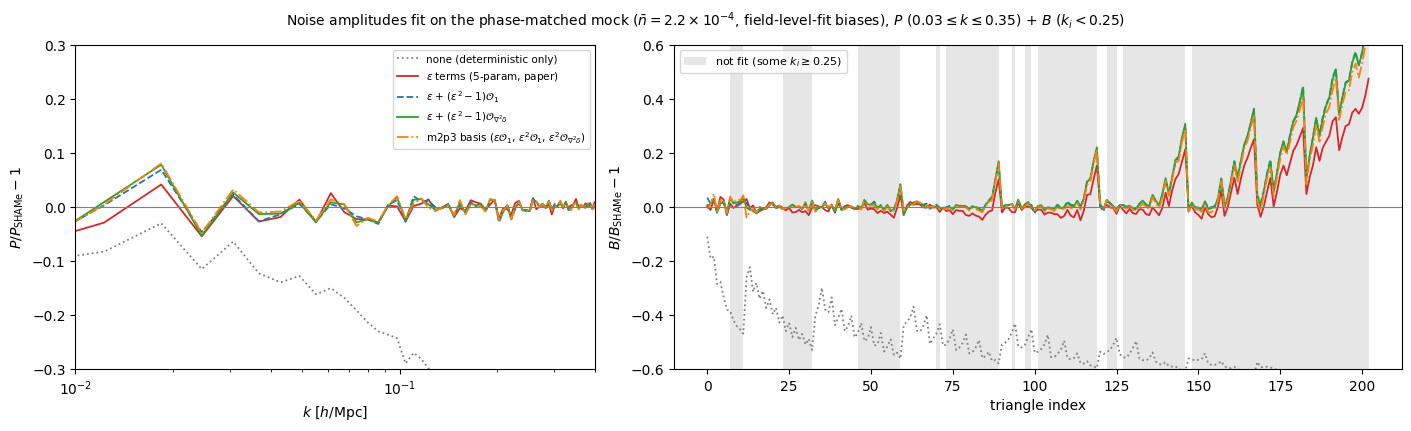

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw=dict(width_ratios=[1, 1.4]), layout='constrained')
style_nm = {'none': ('0.5', ':'), 'eps': ('C3', '-'), 'eps+eps2_O1': ('C0', '--'),
            'eps+eps2_lapl': ('C2', '-'), 'm2p3': ('C1', '-.')}
itri_p = np.arange(len(mB))
axes[1].fill_between(itri_p, -1, 1, where=~mB, step='mid', color='0.9', lw=0, zorder=0,
                     label=r'not fit (some $k_i \geq 0.25$)')
for name, m in models_np.items():
    c, ls = style_nm[name]
    axes[0].plot(k_p, m['P'] / P_sh - 1, color=c, ls=ls, lw=1.3, label=labels_np[name])
    axes[1].plot(itri_p, m['B'] / B_sh - 1, color=c, ls=ls, lw=1.3)
axes[0].set_xscale('log'); axes[0].set_xlim(0.01, 0.4); axes[0].set_ylim(-0.3, 0.3)
axes[0].set_xlabel(r'$k$ [$h$/Mpc]'); axes[0].set_ylabel(r'$P/P_\mathrm{SHAMe} - 1$')
axes[1].set_ylim(-0.6, 0.6)
axes[1].set_xlabel('triangle index'); axes[1].set_ylabel(r'$B/B_\mathrm{SHAMe} - 1$')
for ax in axes:
    ax.axhline(0, color='0.5', lw=0.8)
axes[0].legend(fontsize=7.5); axes[1].legend(fontsize=8, loc='upper left')
fig.suptitle(r'Noise amplitudes fit on the phase-matched mock ($\bar n=2.2\times10^{-4}$, field-level-fit biases), $P$ ($0.03\leq k\leq0.35$) + $B$ ($k_i<0.25$)', fontsize=10)
plt.show()


**Conclusions, §2.4** ($\bar n=2.2\times10^{-4}$, field-level-fit biases; $|\mathrm{model}/\mathrm{SHAMe}-1|$, median / max):

| noise terms | $P$ ($0.03$–$0.35$) | $B$ (fit, $k_i<0.25$) | $B$, $\max k_i>0.3$ (not fit): median, 90th pct of $\lvert\cdot\rvert$ |
|---|---|---|---|
| none | 42% / 59% | 41% / 56% | $-58\%$, 63% |
| $\epsilon$ (5-param, paper) | **0.7% / 2.9%** | **0.9% / 3.7%** | $+1\%$, 27% |
| + $(\epsilon^2-1)\mathcal{O}_1$ | 0.7% / 2.9% | 0.9% / 3.6% | $+1\%$, 29% |
| + $(\epsilon^2-1)\mathcal{O}_{\nabla^2\delta}$ | 0.8% / 2.9% | 0.8% / 3.1% | $+5\%$, 42% |
| m2p3 basis | 0.7% / 3.5% | 0.8% / 4.9% | $+4\%$, 39% |

- **The 5-parameter Gaussian noise model already fits $P$ and $B$ together to $<1\%$ (median), $\lesssim4\%$ (max), once its amplitudes are fit without cosmic variance.** Adding an $\epsilon^2$ term doesn't help: $(\epsilon^2-1)\mathcal{O}_1$ is driven to $\approx0$, and $(\epsilon^2-1)\mathcal{O}_{\nabla^2\delta}$ only trades between amplitudes (loss $3.8\to3.5\times10^{-4}$) while extrapolating *worse* to $k_i>0.3$.
- **Why the extra term isn't needed:** splitting $B$ by order in the amplitudes, SHAMe's stochastic $B$ (about 30–60% of the total) is almost entirely the **noise × noise × density** term ($\propto A^2$), e.g. $\langle(\epsilon\mathcal{O}_i)(\epsilon\mathcal{O}_j)\,\delta\rangle$: the noise variance is modulated by the density field, which is the same physics as Poisson's $(P_1+P_2+P_3)/\bar n$ term. The Gaussian model has this, with 15 amplitude products to shape it. The pure noise³ term that needs $\langle\epsilon^3\rangle\neq0$ (the analogue of Poisson's $1/\bar n^2$) is small on our scales: Poisson's $1/\bar n^2$ is only 2.5–6% of SHAMe's $B$ for $k_i<0.25$, and SHAMe is sub-Poisson. Adding $\epsilon^2$ terms does produce a noise³ part (5% at $k_i<0.25$, 14% at $k_i>0.3$), but the fit doesn't need it.
- **So $B$ needs no extra noise term.** The old §2.3 $B$ mismatch came from the configuration (×2 biases plus noise amplitudes chosen on a cosmic-variance realization), and is gone with the ÷2 SHAMe biases and noise refit on the matched mock (§2.3, §2.5). With free biases and noise, as in the inference, the model has enough freedom to describe SHAMe's 3-point stochasticity on the scales we use.
- **Beyond the fit range ($k_i\gtrsim0.3$) every model overshoots** for some high-$k$ triangles (up to $+50\%$; 90th percentile 27–42%). This is outside our $B$ cut of 0.25.
- **Caveats:** the amplitudes are strongly degenerate (e.g. $A_{\nabla^2}$ flips from $+6.5$ to $-4.2$ when the $\epsilon^2\mathcal{O}_{\nabla^2\delta}$ term is added, at nearly the same loss), so individual best-fit values shouldn't be read physically. Fitting on one noise realization and testing on the other raises the loss from $\sim5\times10^{-4}$ to $\sim1.5\times10^{-3}$ (rms residual $\sim2$–$3\%$), i.e. part of the sub-percent fit is tuning to the specific $\epsilon$; this is the same for every model, so the comparison between models stands. Biases were held fixed at the field-level fit; with biases free too the fits could only improve. One density only.


### 2.5 Noise amplitudes fit on the phase-matched mock: three densities, fixed vs. free biases

**Question.** Which noise amplitudes does each SHAMe density want? This picks the `noisebest` point for the test set and tells us whether the noise priors are wide enough.

**Setup** (`code_auxiliary/select_shame_noisebest.py`):
- For each SHAMe density, fit the 5 noise amplitudes $A$ to SHAMe's $P$ (all $k$) and $B$ (all $k_i<0.25$). The fit minimizes the same reduced $\chi^2$ as the 2026-06-03 selection: $\chi^2_P/n_P+\chi^2_B/n_B$. Errors are Gaussian, from SHAMe's total power.
- Two bias choices:
  - **fixed** at the SHAMe biases (`bias_dict_shame`, ÷2 convention);
  - **free**, fit together with $A$.
- $A_\mathrm{homog}\ge0$; the other amplitudes are unbounded, so the fits show where the data wants them, not where the priors allow. Amplitudes are quoted in library units.
- No cosmic variance (phase-matched). Statistics are the expectation over 4 noise realizations × 2 phases.

The test set uses **n̄ = 2.2e-4, fixed SHAMe biases**. That fit is written to `data/params/params_fixed_biasshame_noisebest_p0_n1.txt`: $A = (2.02, -1.96, 0.98, -0.67, -8.16)$.


In [13]:
fit_nb = np.load(msm.DIR_DATA_SHAME / f'matched_seed{SEED_SH}' / 'noisebest_select' / 'fit.npy', allow_pickle=True).item()
names_nb, bounds_nb = fit_nb['noise_names'], fit_nb['bounds_A']
settings_nb = {'fixed b': ('C3', '-', 'o', 'fixed b (SHAMe)'),
               'free b':  ('k', ':', '^', 'free b')}
nbar_of = {t: float(t.split('nbar')[1]) for t in tags_shame}

print(f"{'nbar':8s} {'biases':20s} {'chi2r P':>7s} {'chi2r B':>7s} {'chi2r Pgm':>9s}   b1,b2,bs2,bl              A: " + ', '.join(names_nb))
for t in tags_shame:
    for s_, (_, _, _, lab) in settings_nb.items():
        r = fit_nb['fits'][(t, s_)]; c = r['chi2_red']
        print(f"{nbar_of[t]:.1e}  {lab:20s} {c['pk']:7.2f} {c['bk']:7.2f} {c['pgm']:9.2f}   {np.round(r['b'], 3)}   {np.round(r['A_lib'], 2)}")
print('\ncurrent priors on A:', bounds_nb)


nbar     biases               chi2r P chi2r B chi2r Pgm   b1,b2,bs2,bl              A: An_homog, An_b1, An_b2, An_bs2, An_bl
1.1e-04  fixed b (SHAMe)         0.56    1.20      2.64   [ 0.529  0.069 -0.109 -1.07 ]   [ 2.44 -2.69  1.93 -1.65 -1.61]
1.1e-04  free b                  0.59    0.78      0.13   [ 0.496  0.117 -0.051  0.64 ]   [ 2.28 -2.58  2.02 -1.8   2.53]
2.2e-04  fixed b (SHAMe)         0.56    0.47      4.39   [ 0.474  0.032 -0.085 -0.824]   [ 2.02 -1.96  0.98 -0.67 -8.16]
2.2e-04  free b                  0.47    0.45      2.63   [ 0.461  0.013 -0.086 -0.968]   [  1.53  -1.12   0.52   0.55 -11.51]
5.4e-04  fixed b (SHAMe)         0.35    0.41      7.99   [ 0.402 -0.005 -0.048 -0.792]   [ 0.01  0.1   0.42 -1.98  9.2 ]
5.4e-04  free b                  0.28    0.39      6.39   [ 0.392 -0.036 -0.056 -1.175]   [ 0.   -0.82  0.31 -0.45  3.78]

current priors on A: {'An_homog': (-5.0, 5.0), 'An_b1': (-5.0, 5.0), 'An_b2': (-3.0, 3.0), 'An_bs2': (-5.0, 5.0), 'An_bl': (-20.0, 20.0)}

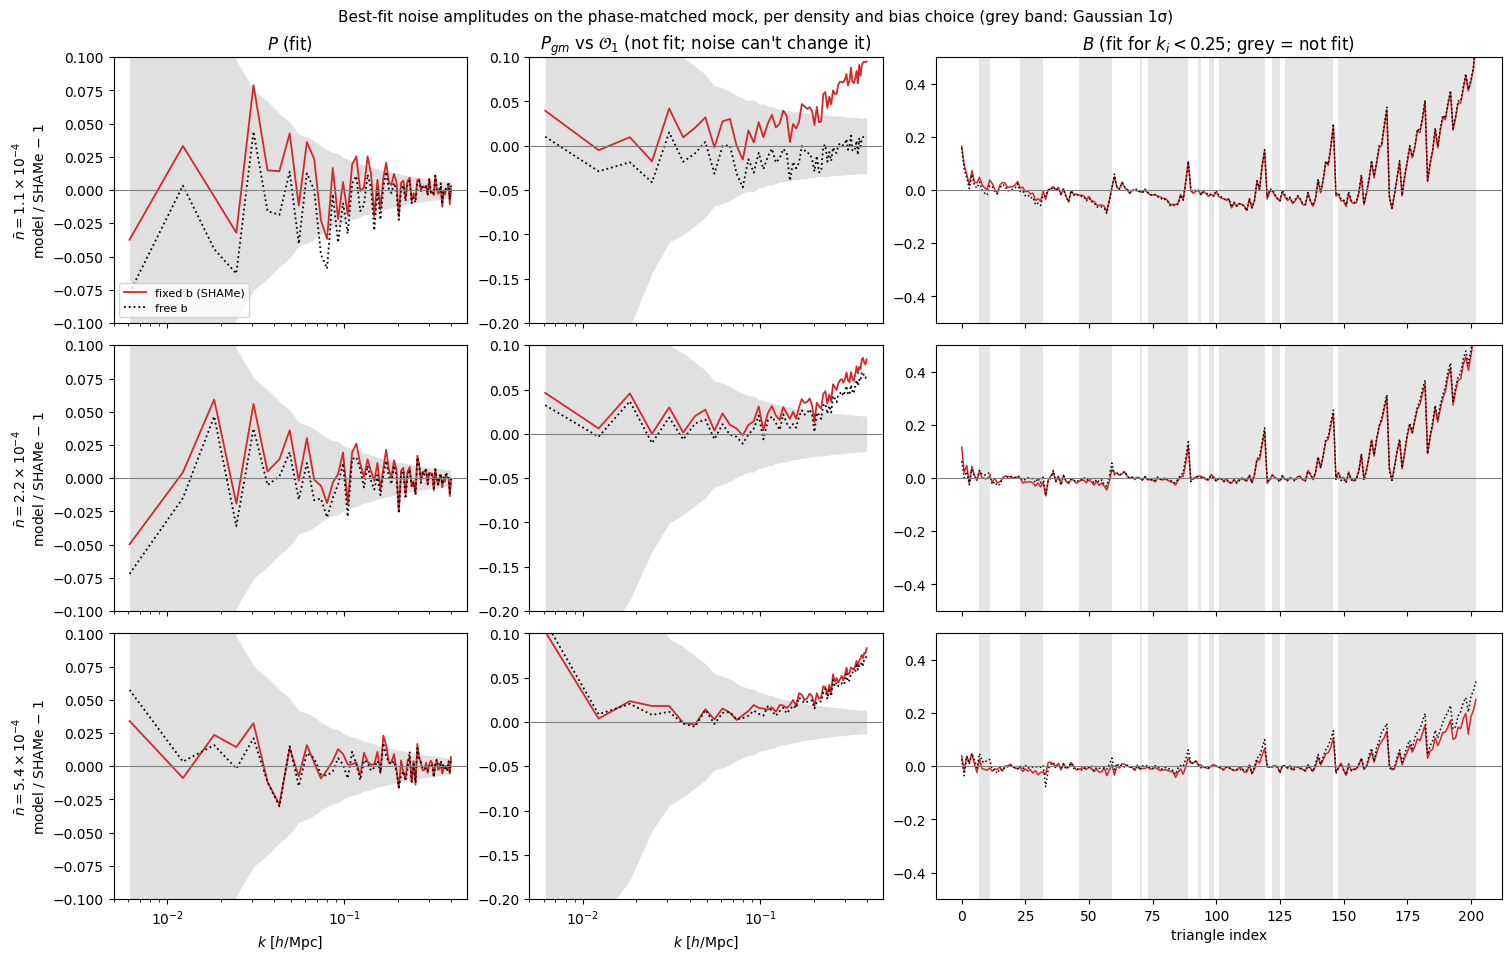

In [14]:
# Figure 1: residuals vs SHAMe for every (density, bias choice)
k_nb, k123_nb, msk_nb = fit_nb['k_pk'], fit_nb['k123'], fit_nb['masks']
itri_nb = np.arange(k123_nb.shape[1])
fig, axes = plt.subplots(3, 3, figsize=(15, 9.5), sharex='col', sharey='col',
                         gridspec_kw=dict(width_ratios=[1, 1, 1.6]), layout='constrained')
for i, t in enumerate(tags_shame):
    sh = fit_nb['targets'][t]
    for s_, (c, ls, _, lab) in settings_nb.items():
        st = fit_nb['fits'][(t, s_)]['stats']
        axes[i, 0].plot(k_nb, st['pk'] / sh['pk'] - 1, color=c, ls=ls, lw=1.3, label=lab)
        axes[i, 1].plot(k_nb, st['pgm'] / sh['pgm'] - 1, color=c, ls=ls, lw=1.3)
        axes[i, 2].plot(itri_nb, st['bk'] / sh['bk'] - 1, color=c, ls=ls, lw=1.1)
    axes[i, 2].fill_between(itri_nb, -1, 1, where=~msk_nb['bk'], step='mid', color='0.9', lw=0, zorder=0)
    for j in range(2):
        axes[i, j].fill_between(k_nb, -np.sqrt(sh['var'][['pk', 'pgm'][j]]) / sh[['pk', 'pgm'][j]],
                                np.sqrt(sh['var'][['pk', 'pgm'][j]]) / sh[['pk', 'pgm'][j]], color='0.88', lw=0, zorder=0)
    axes[i, 0].set_ylabel(rf'$\bar n={nbar_of[t] * 1e4:.1f}\times10^{{-4}}$' + '\nmodel / SHAMe $-$ 1')
for ax in axes.ravel():
    ax.axhline(0, color='0.5', lw=0.8)
for ax in axes[:, :2].ravel():
    ax.set_xscale('log')
axes[0, 0].set_ylim(-0.1, 0.1); axes[0, 1].set_ylim(-0.2, 0.1); axes[0, 2].set_ylim(-0.5, 0.5)
axes[0, 0].set_title(r'$P$ (fit)'); axes[0, 1].set_title(r"$P_{gm}$ vs $\mathcal{O}_1$ (not fit; noise can't change it)")
axes[0, 2].set_title(r'$B$ (fit for $k_i<0.25$; grey = not fit)')
for j, xl in enumerate([r'$k$ [$h$/Mpc]', r'$k$ [$h$/Mpc]', 'triangle index']):
    axes[-1, j].set_xlabel(xl)
axes[0, 0].legend(fontsize=8, loc='lower left')
fig.suptitle('Best-fit noise amplitudes on the phase-matched mock, per density and bias choice (grey band: Gaussian 1σ)', fontsize=11)
plt.show()


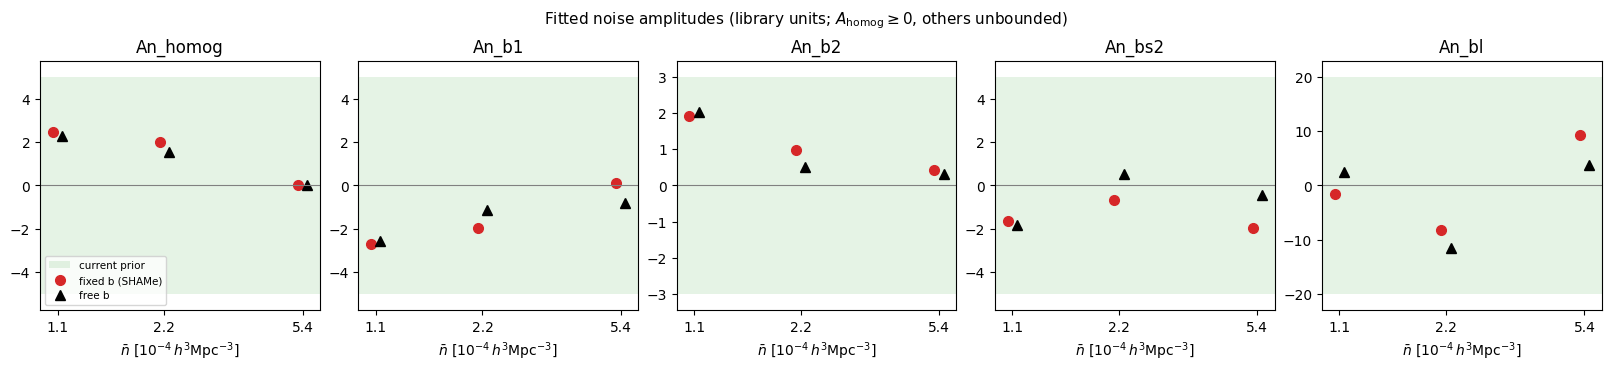

In [15]:
# Figure 2: fitted amplitudes vs density, with the current prior range
fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharex=True, layout='constrained')
x_nb = np.array([nbar_of[t] for t in tags_shame])
for j, n in enumerate(names_nb):
    ax = axes[j]
    lo, hi = bounds_nb[n]
    ax.axhspan(lo, hi, color='C2', alpha=0.12, lw=0, label='current prior' if j == 0 else None)
    for k_, (s_, (c, _, mk, lab)) in enumerate(settings_nb.items()):
        y = [fit_nb['fits'][(t, s_)]['A_lib'][j] for t in tags_shame]
        ax.plot(x_nb * (1 + 0.06 * (k_ - 0.5)), y, color=c, marker=mk, ls='none', ms=7, label=lab if j == 0 else None)
    ax.axhline(0, color='0.5', lw=0.8)
    ax.set_xscale('log'); ax.set_title(n); ax.set_xlabel(r'$\bar n$ [$10^{-4}\,h^3$Mpc$^{-3}$]')
    ax.set_xticks(x_nb, [f'{v * 1e4:.1f}' for v in x_nb], minor=False); ax.set_xticks([], minor=True)
    ymax = max(abs(lo), abs(hi), *[abs(fit_nb['fits'][(t, s_)]['A_lib'][j]) for t in tags_shame for s_ in settings_nb])
    ax.set_ylim(-1.15 * ymax, 1.15 * ymax)
axes[0].legend(fontsize=7.5, loc='lower left')
fig.suptitle(r'Fitted noise amplitudes (library units; $A_\mathrm{homog}\geq0$, others unbounded)', fontsize=11)
plt.show()


**Conclusions, §2.5**

*Fit quality.* With the noise fit, $P$ and $B$ match SHAMe at every density for both bias choices: reduced $\chi^2$ of 0.3–0.6 for $P$ and 0.4–1.2 for $B$. Beyond the $B$ cut, high-$k$ triangles still overshoot, as in §2.4.

*Biases.* $P_{gm}$ doesn't depend on the noise, so it tests the biases directly. Reduced $\chi^2$ for fixed SHAMe vs. free biases: 2.6 vs 0.13 ($1.1\times10^{-4}$), 4.4 vs 2.6 ($2.2\times10^{-4}$), 8.0 vs 6.4 ($5.4\times10^{-4}$). So the SHAMe biases are close to the best the bias model can do, except at the lowest density. (With the old ×2 values: 17.8, 17.5, 8.1.)

*Noise priors.* Largest $|A|$ over all 6 fits, against the v2 priors (`_biasnoisenestv2`, set from these fits):

| | largest $\lvert A\rvert$ (where) | v2 prior |
|---|---|---|
| `An_homog` | 2.44 (1.1e-4, fixed) | ±5 |
| `An_b1` | 2.69 (1.1e-4, fixed) | ±5 |
| `An_b2` | 2.02 (1.1e-4, free) | ±3 |
| `An_bs2` | 1.98 (5.4e-4, fixed) | ±5 |
| `An_bl` | 11.5 (2.2e-4, free) | ±20 |

- **Don't restrict the sign of `An_homog`.** At $5.4\times10^{-4}$ it goes to its floor of 0 for both bias choices, and the $\epsilon\,\mathcal{O}_\delta$ and $\epsilon\nabla^2\delta$ terms carry the noise instead. A prior cut at 0 would pile the posterior against the edge for dense tracers. No other amplitude stays clearly away from 0 either (`An_bl` changes sign between densities), so the sign symmetry can't be removed with a simple bound.
- **The amplitudes are strongly degenerate.** Freeing the biases moves `An_bl` by several units at almost the same $\chi^2$. So the table is a guide to how wide the priors must be, not a set of physical values.
